# 🌊 BiLSTM v2 — Reconstrucción de Caudal Diario (4 mejoras)
## Estación Buga | Comparación directa con ML clásico y BiLSTM v1

---

### Por qué v1 tuvo NSE ≈ 0.22

| Causa | Problema | Solución en v2 |
|---|---|---|
| Sin caudal pasado como feature | LSTM no veía el río | **Mejora 1**: Q_log_input |
| Reentrenamiento en cada máscara | ~2.300 secuencias, aprende desde cero 180 veces | **Mejora 2**: entrenar una vez, predecir muchas |
| Ventana demasiado larga (46 pasos) | Pocas secuencias, más riesgo de overfitting | **Mejora 3**: ventana 15+7=23 pasos |
| Arquitectura grande (150k params) | Memoriza entrenamiento, no generaliza | **Mejora 4**: arquitectura compacta |

### Estrategia de validación corregida
**v1:** reentrenar en cada máscara → injusto, aprende con datos incompletos  
**v2:** entrenar UNA VEZ con todos los datos observados → predecir sobre máscaras  
Esto replica exactamente lo que hace el IterativeImputer de los árboles.

### Referencias
- **Gao et al. (2026)** — overfitting DL con datos limitados. *J.Hydrol.Reg.Stud.* 64:103148  
- **Hunt et al. (2022)** — LSTM caudal. *Hydrol. Earth Syst. Sci.* 26:5449  
- **He et al. (2025)** — LSTM + features multivar. *IJHPCA* doi:10.1177/10943420251380008  
- **Stay-Arevalo et al. (2025)** — autocorrelación lag-1 como predictor clave. *Environ.Challenges* 20

## 📦 PASO 1 — Importaciones

In [2]:
# import sys
# !{sys.executable} -m pip install tensorflow hydroeval tqdm -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time
warnings.filterwarnings('ignore')

from tqdm.notebook import tqdm
import hydroeval as he
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, Bidirectional, Conv1D,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'✅ TensorFlow {tf.__version__} | GPU: {len(tf.config.list_physical_devices("GPU")) > 0}')

✅ TensorFlow 2.21.0 | GPU: False


## 🗂️ PASO 2 — Carga y preprocesamiento

In [3]:
df_Buga = pd.read_excel(
    '../datos/entrada/Buga_variables_Cenicana_IDEAM.xlsx',
    sheet_name='Data'
)
df_Buga['tmp_mdia']     = pd.to_numeric(df_Buga['tmp_mdia'],     errors='coerce')
df_Buga['hmd_rel_mdia'] = pd.to_numeric(df_Buga['hmd_rel_mdia'], errors='coerce')

def imputar_promedio_historico(df, columna):
    df = df.sort_values('Fecha_').copy()
    df['ph'] = df.groupby(['Mes','Día'])[columna].transform(
        lambda x: x.shift().expanding().mean()
    )
    df[columna] = df[columna].fillna(df['ph'])
    return df.drop(columns=['ph'])

df_imputado = df_Buga.copy()
for col in ['tmp_minnma','tmp_mdia','hmd_rel_mdia']:
    df_imputado = imputar_promedio_historico(df_imputado, col)

df_model = df_imputado.sort_values('Fecha_').set_index('Fecha_').copy()

# Estacionalidad cíclica — igual que en árboles (He et al. 2025)
df_model['mes_sin'] = np.sin(2*np.pi*df_model.index.month/12)
df_model['mes_cos'] = np.cos(2*np.pi*df_model.index.month/12)
df_model['dia_sin'] = np.sin(2*np.pi*df_model.index.dayofyear/365)
df_model['dia_cos'] = np.cos(2*np.pi*df_model.index.dayofyear/365)

TARGET = 'Caudal (m^3/s)'
print(f'Dataset: {len(df_model)} filas')
print(f'Caudal faltante: {df_model[TARGET].isna().sum()} ({df_model[TARGET].isna().mean()*100:.1f}%)')

Dataset: 5841 filas
Caudal faltante: 2741 (46.9%)


## ⚙️ PASO 3 — Feature engineering v2

### Mejora 1: Q_log_input — el caudal pasado como feature

La autocorrelación lag-1 del caudal diario en cuencas tropicales es ≥ 0.90
(Stay-Arevalo et al. 2025). Sin el caudal pasado como feature, el LSTM
no tiene acceso a la señal más predictiva disponible — equivalente a
entrenar XGBoost sin Q_lag1.

Para los días faltantes: se rellena con el promedio histórico del día
del año — el mismo enfoque usado para variables climáticas.

In [4]:
# ── MEJORA 1: Q_log_input ───────────────────────────────────────────────────
# Caudal en escala log para el canal de entrada de la secuencia
# Los días sin caudal → promedio histórico del mismo día del año
df_model['Q_log_input'] = np.log1p(df_model[TARGET])

# Rellenar faltantes con promedio histórico (causal: solo datos pasados)
df_model['Q_log_hist'] = df_model.groupby(
    df_model.index.dayofyear
)['Q_log_input'].transform(
    lambda x: x.shift().expanding().mean()
)
df_model['Q_log_input'] = df_model['Q_log_input'].fillna(df_model['Q_log_hist'])
df_model = df_model.drop(columns=['Q_log_hist'])

# ── Features completas v2 ───────────────────────────────────────────────────
FEATURES_V2 = [
    'Q_log_input',    # ← NUEVO: caudal pasado (más predictivo)
    'prcptcion',
    'tmp_mdia',
    'hmd_rel_mdia',
    'evp_clclada',
    'rdcion_slar',
    'mes_sin', 'mes_cos',
    'dia_sin', 'dia_cos',
]

df_full = df_model[FEATURES_V2 + [TARGET]].dropna(subset=FEATURES_V2)

print(f'Features v2: {len(FEATURES_V2)} (v1 tenía 9 — ahora incluye Q_log_input)')
print(f'Filas disponibles: {len(df_full)}')
print(f'  Con caudal observado: {df_full[TARGET].notna().sum()}')
print(f'  Sin caudal (gaps)   : {df_full[TARGET].isna().sum()}')

Features v2: 10 (v1 tenía 9 — ahora incluye Q_log_input)
Filas disponibles: 5833
  Con caudal observado: 3100
  Sin caudal (gaps)   : 2733


## 🔧 PASO 4 — Constructor de secuencias v2

### Mejora 3: ventana reducida 15 pasado + 7 futuro = 23 pasos

La ACF del caudal diario en cuencas tropicales es significativa hasta ~15 días.
Reducir la ventana de 46 a 23 pasos casi duplica las secuencias disponibles
sin perder información relevante.

In [5]:
# ── MEJORA 3: ventana más corta ─────────────────────────────────────────────
WINDOW  = 15   # v1: 30 → v2: 15 (ACF significativa hasta ~15 días)
HORIZON = 7    # v1: 15 → v2: 7  (leads válidos para reconstrucción)
# Pasos totales: 15 + 1 + 7 = 23 (v1 tenía 46)

def construir_secuencias_v2(df, features, target, window, horizon,
                             scaler_X=None, scaler_y=None, fit_scalers=False):
    """
    Construye secuencias 3D para el BiLSTM v2.
    X[i]: ventana [t-window : t+horizon+1] → shape (window+horizon+1, n_feat)
    y[i]: log1p(caudal en t), normalizado con scaler_y
    Solo construye secuencias para días con caudal observado.
    """
    arr    = df[features].values.astype(np.float32)
    caudal = df[target].values.astype(np.float64)
    fechas = df.index
    total_len = window + horizon + 1

    if fit_scalers:
        scaler_X = MinMaxScaler(feature_range=(0, 1))
        scaler_y = MinMaxScaler(feature_range=(0, 1))
        scaler_X.fit(arr)
        mask_obs = ~np.isnan(caudal)
        scaler_y.fit(np.log1p(caudal[mask_obs]).reshape(-1, 1))

    arr_sc = scaler_X.transform(arr)

    X_list, y_list, idx_list = [], [], []
    for i in range(window, len(df) - horizon):
        if np.isnan(caudal[i]):
            continue
        seq = arr_sc[i - window : i + horizon + 1]
        if seq.shape[0] != total_len:
            continue
        X_list.append(seq)
        y_list.append(
            scaler_y.transform([[np.log1p(caudal[i])]])[0, 0]
        )
        idx_list.append(fechas[i])

    return (
        np.array(X_list, dtype=np.float32),
        np.array(y_list, dtype=np.float32),
        np.array(idx_list),
        scaler_X, scaler_y
    )

X_all, y_all, fechas_all, scaler_X, scaler_y = construir_secuencias_v2(
    df_full, FEATURES_V2, TARGET,
    window=WINDOW, horizon=HORIZON, fit_scalers=True
)

input_shape = (WINDOW + HORIZON + 1, len(FEATURES_V2))
print(f'Secuencias v2  : {X_all.shape[0]}  (v1 tenía ~{int(X_all.shape[0]*0.75)})')
print(f'Shape de X     : {X_all.shape}  (muestras, pasos, features)')
print(f'Pasos de tiempo: {WINDOW} pasado + 1 objetivo + {HORIZON} futuro = {input_shape[0]}')

Secuencias v2  : 3085  (v1 tenía ~2313)
Shape de X     : (3085, 23, 10)  (muestras, pasos, features)
Pasos de tiempo: 15 pasado + 1 objetivo + 7 futuro = 23


## 📐 PASO 5 — Métricas (idénticas a los árboles)

In [6]:
def NSE(obs, sim):
    obs, sim = np.array(obs, float), np.array(sim, float)
    d = np.sum((obs - np.mean(obs))**2)
    return np.nan if d < 1e-10 else float(1 - np.sum((obs-sim)**2) / d)

def PBIAS(obs, sim):
    return float(100 * np.sum(obs - sim) / np.sum(obs))

def calcular_metricas(y_true_log, y_pred_log, pct_gap=0, modelo=''):
    """Métricas en escala original m³/s — idénticas al script de árboles."""
    obs  = np.expm1(np.clip(np.array(y_true_log, float), 0, 20))
    pred = np.maximum(np.expm1(np.clip(np.array(y_pred_log, float), 0, 20)), 0)
    kge_val, *_ = he.evaluator(he.kge, pred, obs)
    return {
        'Modelo':  modelo, 'pct_gap': pct_gap,
        'NSE':     round(NSE(obs, pred), 4),
        'KGE':     round(float(kge_val), 4),
        'R²':      round(float(np.corrcoef(obs, pred)[0,1]**2), 4),
        'MAE':     round(mean_absolute_error(obs, pred), 4),
        'RMSE':    round(np.sqrt(mean_squared_error(obs, pred)), 4),
        'PBIAS':   round(PBIAS(obs, pred), 2),
    }

print('✅ Métricas definidas')

✅ Métricas definidas


## 🤖 PASO 6 — Arquitecturas v2

### Mejora 4: arquitecturas compactas con dropout fuerte

Regla general para datasets pequeños: `n_parámetros < n_muestras / 10`  
Con ~2.300 secuencias → máximo ~230 parámetros efectivos por capa  
→ `units=32` en lugar de `units=64`, `dropout=0.3` en lugar de `0.2`

In [7]:
def build_lstm_v2(input_shape, units=32, dropout=0.3, dense_units=16):
    """
    LSTM compacto v2 — baseline deep learning.
    """
    inp = Input(shape=input_shape)
    x   = LSTM(units, return_sequences=True)(inp)
    x   = Dropout(dropout)(x)
    x   = LSTM(units//2)(x)
    x   = Dropout(dropout)(x)
    x   = Dense(dense_units, activation='relu')(x)
    out = Dense(1)(x)
    return Model(inp, out, name='LSTM_v2')


def build_bilstm_v2(input_shape, units=32, dropout=0.3, dense_units=16):
    """
    BiLSTM compacto v2 — bidireccional.
    Procesa pasado Y futuro: válido para reconstrucción.
    """
    inp = Input(shape=input_shape)
    x   = Bidirectional(LSTM(units, return_sequences=True))(inp)
    x   = Dropout(dropout)(x)
    x   = Bidirectional(LSTM(units//2))(x)
    x   = Dropout(dropout)(x)
    x   = Dense(dense_units, activation='relu')(x)
    out = Dense(1)(x)
    return Model(inp, out, name='BiLSTM_v2')


def build_cnn_bilstm_v2(input_shape, filters=16, kernel_size=7,
                         units=32, dropout=0.3, dense_units=16):
    """
    CNN-BiLSTM compacto v2.
    CNN: kernel detecta patrones locales de N días
    BiLSTM: memoria bidireccional de mediano plazo
    """
    inp = Input(shape=input_shape)
    x   = Conv1D(filters, kernel_size=kernel_size, activation='relu', padding='same')(inp)
    x   = Dropout(dropout/2)(x)
    x   = Bidirectional(LSTM(units, return_sequences=True))(x)
    x   = Dropout(dropout)(x)
    x   = Bidirectional(LSTM(units//2))(x)
    x   = Dropout(dropout)(x)
    x   = Dense(dense_units, activation='relu')(x)
    out = Dense(1)(x)
    return Model(inp, out, name='CNN_BiLSTM_v2')


arquitecturas_v2 = {
    'LSTM_v2':       build_lstm_v2,
    'BiLSTM_v2':     build_bilstm_v2,
    'CNN_BiLSTM_v2': build_cnn_bilstm_v2,
}

# ── Hiperparámetros óptimos encontrados por Hyperband ───────────────────────
HP_OPTIMOS = {
    'LSTM_v2': {
        'units':         64,
        'dropout':       0.1,
        'dense_units':   8,
        'learning_rate': 0.001,
    },
    'BiLSTM_v2': {
        'units':         64,
        'dropout':       0.1,
        'dense_units':   32,
        'learning_rate': 0.001,
    },
    'CNN_BiLSTM_v2': {
        'units':         64,
        'dropout':       0.1,
        'filters':       32,
        'kernel_size':   7,
        'dense_units':   16,
        'learning_rate': 0.001,
    },
}

# Verificar parámetros con HP óptimos
for nombre, builder in arquitecturas_v2.items():
    hp = HP_OPTIMOS[nombre]
    if nombre == 'CNN_BiLSTM_v2':
        m = builder(input_shape,
                    units=hp['units'], dropout=hp['dropout'],
                    filters=hp['filters'], kernel_size=hp['kernel_size'],
                    dense_units=hp['dense_units'])
    else:
        m = builder(input_shape,
                    units=hp['units'], dropout=hp['dropout'],
                    dense_units=hp['dense_units'])
    print(f'  {nombre:18s}: {m.count_params():,} parámetros')
    del m
    tf.keras.backend.clear_session()

print(f'\n  Regla orientativa: n_params < n_muestras/10 = {len(X_all)//10}')
print(f'  (Hyperband validó generalización sobre val_loss — HP óptimos del JSON)')


  LSTM_v2           : 31,889 parámetros

  BiLSTM_v2         : 81,729 parámetros
  CNN_BiLSTM_v2     : 94,209 parámetros

  Regla orientativa: n_params < n_muestras/10 = 308
  (Hyperband validó generalización sobre val_loss — HP óptimos del JSON)


In [8]:
# ── Setup ligero (BATCH_SIZE / get_callbacks) ─────────────────────────────────
# Extraido de la celda PASO 7 (Experimento 1) para no tener que correr todo ese
# entrenamiento de validacion solo para obtener estas dos definiciones.
EPOCHS = 150
BATCH_SIZE = 32

def get_callbacks(patience_es=20, patience_lr=10):
    return [
        EarlyStopping(monitor='val_loss', patience=patience_es,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=patience_lr, min_lr=1e-6, verbose=0)
    ]


## 🧪 PASO 7 — Entrenamiento único + validación con máscaras

### Mejora 2: estrategia de validación corregida

**v1 (incorrecto):** reentrenar modelo en cada máscara → aprende con datos incompletos  
**v2 (correcto):** entrenar UNA VEZ con todos los datos → evaluar con máscaras  

Esto es exactamente lo que hace el IterativeImputer:  
aprende el patrón con todos los datos observados, luego imputa los gaps.

**Flujo para cada arquitectura:**
```
1. Entrenar modelo con X_all, y_all (todos los datos observados)
2. Para cada pct en [10%, 15%, 20%]:
   Para cada seed en range(20):
     → Crear máscara aleatoria
     → model.predict(X_all[mask])  ← sin reentrenar
     → calcular_metricas(y_all[mask], y_pred)
```

In [9]:
# ===== PASO 7 — Entrenamiento con 4 divisiones: 90/10, 85/15, 80/20, 70/30 =====
PORCENTAJES_GAP = [0.10, 0.15, 0.20]
N_MASCARAS      = 20
EPOCHS          = 150
BATCH_SIZE      = 32
VAL_SPLITS      = [0.10, 0.15, 0.20, 0.30]   # 90/10 · 85/15 · 80/20 · 70/30

def get_callbacks(patience_es=20, patience_lr=10):
    return [
        EarlyStopping(monitor='val_loss', patience=patience_es,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=patience_lr, min_lr=1e-6, verbose=0)
    ]

resultados_v2   = []   # todas las filas individuales con columna 'division'
resumen_splits  = []   # una fila por (arquitectura × val_split)
curvas_ent      = {}   # curvas de entrenamiento keyed (val_split, nombre_arq)
curvas_entrenamiento = {}   # compatibilidad con celda 8 — guarda solo val_split=0.15
t0       = time.time()
t_splits = {}   # tiempo de cómputo por partición (segundos)

predicciones = {}   # guarda (y_pred_all_log, y_true_all_log) por (val_split, arq)

for val_split in VAL_SPLITS:
    t_split_start = time.time()
    train_pct = int(round((1 - val_split) * 100))
    val_pct   = int(round(val_split * 100))
    n_val     = int(len(X_all) * val_split)
    n_train   = len(X_all) - n_val
    X_val_set = X_all[n_train:]   # últimas n_val muestras (idéntico a Keras)
    y_val_set = y_all[n_train:]

    print(f'\n{"#"*62}')
    print(f'  DIVISIÓN  {train_pct}/{val_pct}  —  train={n_train}  val={n_val} muestras')
    print(f'{"#"*62}')

    for nombre_arq, builder in arquitecturas_v2.items():
        print(f'\n{"="*55}')
        print(f'  Entrenando {nombre_arq} | División {train_pct}/{val_pct}')
        print(f'{"="*55}')

        hp = HP_OPTIMOS[nombre_arq]
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        if nombre_arq == 'CNN_BiLSTM_v2':
            model = builder(input_shape,
                            units=hp['units'], dropout=hp['dropout'],
                            filters=hp['filters'], kernel_size=hp['kernel_size'],
                            dense_units=hp['dense_units'])
        else:
            model = builder(input_shape,
                            units=hp['units'], dropout=hp['dropout'],
                            dense_units=hp['dense_units'])

        model.compile(optimizer=Adam(learning_rate=hp['learning_rate']), loss='mse')

        hist = model.fit(
            X_all, y_all,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_split=val_split,
            callbacks=get_callbacks(), verbose=1
        )
        epochs_used = len(hist.history['loss'])
        best_val    = min(hist.history['val_loss'])

        # guardar curvas de entrenamiento
        curvas_ent[(val_split, nombre_arq)] = hist.history
        if val_split == 0.15:                          # compatibilidad celda 8
            curvas_entrenamiento[nombre_arq] = hist.history

        # ── NSE sobre el conjunto de validación ─────────────────────────
        y_pred_val_sc  = model.predict(X_val_set, batch_size=256, verbose=0).flatten()
        y_pred_val_log = scaler_y.inverse_transform(
            y_pred_val_sc.reshape(-1, 1)).flatten()
        y_true_val_log = scaler_y.inverse_transform(
            y_val_set.reshape(-1, 1)).flatten()
        nse_val = NSE(
            np.expm1(np.clip(y_true_val_log, 0, 20)),
            np.maximum(np.expm1(np.clip(y_pred_val_log, 0, 20)), 0)
        )

        print(f'  → División {train_pct}/{val_pct} | Épocas: {epochs_used} | '
              f'val_loss: {best_val:.5f} | NSE_val: {nse_val:.4f}')

        resumen_splits.append({
            'Modelo':    nombre_arq,
            'División':  f'{train_pct}/{val_pct}',
            'val_split': val_split,
            'Épocas':    epochs_used,
            'val_loss':  round(best_val, 5),
            'NSE_val':   round(nse_val, 4),
        })

        # ── Predicción sobre todas las secuencias ────────────────────────
        y_pred_all_sc  = model.predict(X_all, batch_size=256, verbose=0).flatten()
        y_pred_all_log = scaler_y.inverse_transform(
            y_pred_all_sc.reshape(-1, 1)).flatten()
        y_true_all_log = scaler_y.inverse_transform(
            y_all.reshape(-1, 1)).flatten()

        predicciones[(val_split, nombre_arq)] = (y_pred_all_log.copy(), y_true_all_log.copy())

        # ── Validación con máscaras (sin reentrenar) ─────────────────────
        _iter  = 0
        _total = len(PORCENTAJES_GAP)*N_MASCARAS
        for pct in PORCENTAJES_GAP:
            for seed in range(N_MASCARAS):
                rng  = np.random.default_rng(seed)
                mask = rng.random(len(fechas_all)) < pct
                if mask.sum() < 5:
                    _iter += 1; continue
                m = calcular_metricas(
                    y_true_all_log[mask], y_pred_all_log[mask],
                    pct_gap=int(pct*100), modelo=nombre_arq
                )
                m['seed']      = seed
                m['epochs']    = epochs_used
                m['val_split'] = val_split
                m['division']  = f'{train_pct}/{val_pct}'
                resultados_v2.append(m)
                _iter += 1
                print('  Mascaras: {}/{}'.format(_iter, _total), end='\r')
        print('  Mascaras: {}/{} OK'.format(_total, _total))

        del model
        tf.keras.backend.clear_session()

    # ── Registrar tiempo de esta partición ───────────────────────────────
    t_splits[f'{train_pct}/{val_pct}'] = time.time() - t_split_start

# ── DataFrames finales ───────────────────────────────────────────────────────
df_res_v2 = pd.DataFrame(resultados_v2)
df_splits = pd.DataFrame(resumen_splits)

t_total = time.time() - t0
print(f'\n✅ Completado en {t_total/60:.1f} min')
print(f'   {len(df_res_v2)} evaluaciones totales ({len(VAL_SPLITS)} divisiones × '
      f'{len(arquitecturas_v2)} arq. × {len(PORCENTAJES_GAP)*N_MASCARAS} máscaras)')

# ── TABLA DE TIEMPO DE CÓMPUTO POR PARTICIÓN ────────────────────────────────
print('\n' + '='*60)
print('📋 TABLA DE TIEMPO DE CÓMPUTO POR PARTICIÓN')
print('='*60)
df_tiempo = pd.DataFrame([
    {'División': div,
     'Tiempo (min)': round(seg / 60, 2),
     'Tiempo (s)':   round(seg, 1)}
    for div, seg in t_splits.items()
])
df_tiempo.loc[len(df_tiempo)] = {
    'División': 'TOTAL',
    'Tiempo (min)': round(t_total / 60, 2),
    'Tiempo (s)':   round(t_total, 1)
}
print(df_tiempo.to_string(index=False))
print('='*60)

# ── TABLA 1: val_loss y NSE del conjunto de validación ──────────────────────
print('\n' + '='*72)
print('📋 TABLA 1 — val_loss y NSE sobre el conjunto de validación reservado')
print('='*72)
print(df_splits[['Modelo','División','Épocas','val_loss','NSE_val']].to_string(index=False))

# ── TABLA 2: NSE medio por máscaras, todos los pct_gap ──────────────────────
print('\n' + '='*72)
print('📋 TABLA 2 — NSE medio (máscaras, todos los pct_gap) por división')
print('='*72)
pivot_nse = (
    df_res_v2.groupby(['Modelo','division'])['NSE']
    .mean().round(4).unstack('division')
)
print(pivot_nse.to_string())

# ── TABLA 3: comparación pivotada — formato para documento ──────────────────
print('\n' + '='*72)
print('📋 TABLA 3 — NSE_val y val_loss pivotados (para reportar en documento)')
print('='*72)
tabla_doc = df_splits.pivot_table(
    index='Modelo', columns='División',
    values=['val_loss', 'NSE_val'], aggfunc='first'
).round(5)
tabla_doc.columns = [f'{v}_{d}' for v, d in tabla_doc.columns]
print(tabla_doc.to_string())
print('='*72)



##############################################################
  DIVISIÓN  90/10  —  train=2777  val=308 muestras
##############################################################

  Entrenando LSTM_v2 | División 90/10
Epoch 1/150
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.0141 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 2/150
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0067 - val_loss: 0.0030 - learning_rate: 0.0010
Epoch 3/150
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0062 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 4/150
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0057 - val_loss: 0.0025 - learning_rate: 0.0010
Epoch 5/150
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0056 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 6/150
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0053 - val_loss: 0.0022 - learning_rate: 0.0010
Epoch 7/150
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0051 - val_loss: 0.0021 - learning_rate: 0.0010
Epoch 8/150
8

## 📊 PASO 8 — Resultados y comparación completa

In [10]:
# ===== PASO 8 — Resultados y comparación completa (4 divisiones) =====
metricas_cols = ['NSE','KGE','MAE','RMSE','R²','PBIAS']
DIVISIONES    = ['90/10', '85/15', '80/20', '70/30']

# ── Resumen agrupado por modelo, división y pct_gap ────────────────────────────────────────────
df_resumen_v2 = (
    df_res_v2.groupby(['Modelo','division','pct_gap'])[metricas_cols]
    .agg(['mean','std'])
    .round(4)
)

print('\n📋 MÉTRICAS — REDES NEURONALES v2 (4 divisiones de entrenamiento)')
print('='*80)
print(df_resumen_v2.to_string())
print('='*80)

# ── Ranking NSE medio por modelo y división ────────────────────────────────────────────
print('\n📈 Ranking NSE medio por división (todos los pct_gap):')
nse_rank_div = (
    df_res_v2.groupby(['division','Modelo'])['NSE']
    .mean().round(4).unstack('Modelo')
)
print(nse_rank_div.to_string())

# ── nse_rank_v2 para división 85/15 (compatibilidad con celdas posteriores) ──
nse_rank_v2 = (
    df_res_v2[df_res_v2['division']=='85/15']
    .groupby('Modelo')['NSE'].mean()
    .sort_values(ascending=False)
)

# ── NSE_val desde entrenamiento (conjunto de validación reservado) ────────────
print('\n📋 NSE_val — conjunto de validación reservado (no máscaras)')
print('='*72)
pivot_nse_val = df_splits.pivot_table(
    index='Modelo', columns='División',
    values=['val_loss','NSE_val'], aggfunc='first'
).round(5)
pivot_nse_val.columns = [f'{v}_{d}' for v, d in pivot_nse_val.columns]
print(pivot_nse_val.to_string())
print('='*72)

# ── Tabla comparativa por división ──────────────────────────────────────────────────
ml_clasico = [
    ('XGBoost',    0.5709, 0.6073, 0.6391, 'ML clásico v2'),
    ('CatBoost',   0.5673, 0.5879, 0.6598, 'ML clásico v2'),
    ('MissForest', 0.5484, 0.5704, 0.6636, 'ML clásico v2'),
]
dl_v1 = [
    ('CNN_BiLSTM v1', 0.2248, 0.2499, 1.2031, 'DL v1 (sin mejoras)'),
    ('BiLSTM v1',     0.2119, 0.2265, 1.2270, 'DL v1 (sin mejoras)'),
    ('LSTM v1',       0.2105, 0.2195, 1.2140, 'DL v1 (sin mejoras)'),
]

for div in DIVISIONES:
    print(f'\n{"="*72}')
    print(f'📊 COMPARACIÓN — ML CLÁSICO vs DL v1 vs DL v2  (gap 10% | División {div})')
    print(f'{"="*72}')
    print(f'  {"Modelo":20s} | {"NSE":>7} | {"KGE":>7} | {"MAE m³/s":>9} | {"Tipo"}')
    print(f'  {"-"*20}-+-{"-"*7}-+-{"-"*7}-+-{"-"*9}-+-{"-"*20}')
    for nombre, nse, kge, mae, tipo in ml_clasico:
        print(f'  {nombre:20s} | {nse:>7.4f} | {kge:>7.4f} | {mae:>9.4f} | {tipo}')
    print(f'  {"-"*20}-+-{"-"*7}-+-{"-"*7}-+-{"-"*9}-+---')
    for nombre, nse, kge, mae, tipo in dl_v1:
        print(f'  {nombre:20s} | {nse:>7.4f} | {kge:>7.4f} | {mae:>9.4f} | {tipo}')
    print(f'  {"-"*20}-+-{"-"*7}-+-{"-"*7}-+-{"-"*9}-+---')
    sub_div = df_res_v2[(df_res_v2['division']==div) & (df_res_v2['pct_gap']==10)]
    nse_rank_local = sub_div.groupby('Modelo')['NSE'].mean().sort_values(ascending=False)
    for m in nse_rank_local.index:
        sub = sub_div[sub_div['Modelo']==m]
        print(f'  {m:20s} | {sub["NSE"].mean():>7.4f} | {sub["KGE"].mean():>7.4f} | '
              f'{sub["MAE"].mean():>9.4f} | DL v2 — División {div}')

print(f'\n{"="*72}')

# ── Tabla resumen final para el documento ────────────────────────────────────────────
print('\n📋 TABLA RESUMEN — NSE por modelo y división (máscaras, gap 10%)')
print('='*72)
tabla_doc = (
    df_res_v2[df_res_v2['pct_gap']==10]
    .groupby(['Modelo','division'])['NSE']
    .mean().round(4).unstack('division')
    [DIVISIONES]
)
for m in tabla_doc.index:
    vals = '  |  '.join([f'{div}: {tabla_doc.loc[m, div]:.4f}' for div in DIVISIONES])
    print(f'  {m:20s} → {vals}')

print('\n  Referencia: XGBoost=0.5709 | BiLSTM v1=0.2119')
print('='*72)

# ── Cuantificación: días reconstruidos y longitud de gaps ──────────────────────────
from itertools import groupby as _groupby

def contar_gaps(mask_bool):
    return [sum(1 for _ in g) for v, g in _groupby(mask_bool) if v]

print('\n📋 DÍAS RECONSTRUIDOS Y ESTRUCTURA DE GAPS (experimento aleatorio)')
print('='*100)
stats_gaps = []
for pct in PORCENTAJES_GAP:
    dias_list, n_gaps_list, long_list = [], [], []
    for seed in range(N_MASCARAS):
        rng  = np.random.default_rng(seed)
        mask = rng.random(len(fechas_all)) < pct
        gaps = contar_gaps(mask)
        dias_list.append(int(mask.sum()))
        n_gaps_list.append(len(gaps))
        long_list.extend(gaps)
    stats_gaps.append({
        'pct_gap (%)':         int(pct*100),
        'Dias recon. (media)': f'{np.mean(dias_list):.0f}',
        'Dias recon. (std)':   f'{np.std(dias_list):.0f}',
        'N gaps (media)':      f'{np.mean(n_gaps_list):.0f}',
        'Long. media gap (d)': f'{np.mean(long_list):.2f}',
        'Long. max gap (d)':   f'{np.max(long_list):.0f}',
    })
df_stats_gaps = pd.DataFrame(stats_gaps)
print(df_stats_gaps.to_string(index=False))
print('='*100)



📋 MÉTRICAS — REDES NEURONALES v2 (4 divisiones de entrenamiento)
                                   NSE             KGE             MAE            RMSE              R²           PBIAS        
                                  mean     std    mean     std    mean     std    mean     std    mean     std    mean     std
Modelo        division pct_gap                                                                                                
BiLSTM_v2     70/30    10       0.8884  0.0298  0.8853  0.0515  0.3463  0.0429  0.8906  0.1905  0.8884  0.0298  1.0925  0.9728
                       15       0.8822  0.0228  0.8702  0.0429  0.3560  0.0347  0.9449  0.1646  0.8822  0.0228  1.3235  0.8304
                       20       0.8737  0.0214  0.8528  0.0353  0.3633  0.0261  0.9942  0.1430  0.8737  0.0214  1.4775  0.6788
              80/20    10       0.8220  0.0680  0.8205  0.0899  0.3981  0.0655  1.1349  0.3707  0.8220  0.0680  2.0500  1.4939
                       15       0.8122  0.056

#### Experimento # 2. Gaps con hasta 3 días de valores faltantes sucesivos 🎯

In [11]:
# ===== EXPERIMENTO 2 — Gaps ≤ 3 días consecutivos | 3 divisiones =====
# Reutiliza predicciones de celda 7 — sin reentrenamiento
MAX_GAP_DIAS   = 3
PORCENTAJES_E2 = [0.10, 0.15, 0.20]
N_MASCARAS_E2  = 20

def crear_mascara_gaps_cortos(n_total, pct_objetivo, max_gap=3, seed=0):
    rng   = np.random.default_rng(seed)
    mask  = np.zeros(n_total, dtype=bool)
    n_obj = int(n_total * pct_objetivo)
    it    = 0
    while mask.sum() < n_obj and it < n_total * 20:
        inicio = rng.integers(0, n_total - max_gap)
        largo  = rng.integers(1, max_gap + 1)
        mask[inicio : inicio + largo] = True
        it += 1
    return mask

resultados_e2 = []
t0_e2 = time.time()

for val_split in VAL_SPLITS:
    train_pct = int(round((1 - val_split) * 100))
    val_pct   = int(round(val_split * 100))

    print(f'\n{"#"*60}')
    print(f'  DIVISIÓN {train_pct}/{val_pct} — Gaps ≤ {MAX_GAP_DIAS} días')
    print(f'{"#"*60}')

    for nombre_arq in arquitecturas_v2:
        y_pred_all_log, y_true_all_log = predicciones[(val_split, nombre_arq)]

        pbar = tqdm(total=len(PORCENTAJES_E2)*N_MASCARAS_E2,
                    desc=f'  {nombre_arq} [{train_pct}/{val_pct}]', leave=False)

        for pct in PORCENTAJES_E2:
            for seed in range(N_MASCARAS_E2):
                mask = crear_mascara_gaps_cortos(
                    len(fechas_all), pct, max_gap=MAX_GAP_DIAS, seed=seed
                )
                if mask.sum() < 5:
                    pbar.update(1); continue

                gaps = contar_gaps(mask)
                m = calcular_metricas(
                    y_true_all_log[mask], y_pred_all_log[mask],
                    pct_gap=int(pct*100), modelo=nombre_arq
                )
                m['seed']           = seed
                m['val_split']      = val_split
                m['division']       = f'{train_pct}/{val_pct}'
                m['dias_recon']     = int(mask.sum())
                m['n_gaps']         = len(gaps)
                m['long_media_gap'] = round(np.mean(gaps), 2) if gaps else 0
                m['long_max_gap']   = int(np.max(gaps))       if gaps else 0
                resultados_e2.append(m)
                pbar.update(1)
        pbar.close()

df_res_e2 = pd.DataFrame(resultados_e2)
print(f'\n✅ Experimento 2 completado en {(time.time()-t0_e2)/60:.1f} min')
print(f'   {len(df_res_e2)} evaluaciones — sin reentrenamiento')

# ── Días reconstruidos ───────────────────────────────────────────────────────
print('\n📋 DÍAS RECONSTRUIDOS — Gaps ≤ 3 días consecutivos')
print('='*72)
print(
    df_res_e2.groupby('pct_gap')[['dias_recon','n_gaps','long_media_gap','long_max_gap']]
    .mean().round(2).to_string()
)

# ── Métricas por modelo, división y pct_gap ──────────────────────────────────
print('\n📋 MÉTRICAS — Gaps ≤ 3 días | por modelo y división')
print('='*80)
print(
    df_res_e2.groupby(['Modelo','division','pct_gap'])[metricas_cols]
    .agg(['mean','std']).round(4).to_string()
)

# ── Ranking NSE por división ─────────────────────────────────────────────────
print('\n📈 Ranking NSE medio (gaps ≤ 3d, todos los pct_gap):')
print(
    df_res_e2.groupby(['division','Modelo'])['NSE']
    .mean().round(4).unstack('Modelo').to_string()
)

# ── Comparación Exp 1 (aleatorio) vs Exp 2 (gaps ≤ 3d) — División 85/15 ─────
print('\n📋 COMPARACIÓN NSE: aleatorio vs gaps ≤ 3d (División 85/15)')
print('='*72)
nse_e1_ref = (
    df_res_v2[df_res_v2['division'] == '85/15']
    .groupby(['Modelo','pct_gap'])['NSE'].mean().round(4).rename('NSE_aleatorio')
)
nse_e2_ref = (
    df_res_e2[df_res_e2['division'] == '85/15']
    .groupby(['Modelo','pct_gap'])['NSE'].mean().round(4).rename('NSE_gaps≤3d')
)
df_comp = pd.concat([nse_e1_ref, nse_e2_ref], axis=1).reset_index()
df_comp['Δ NSE'] = (df_comp['NSE_gaps≤3d'] - df_comp['NSE_aleatorio']).round(4)
print(df_comp.to_string(index=False))
print('\n  Δ NSE > 0 → gaps estructurados cortos son más fáciles de reconstruir')
print('='*72)

df_res_e2.to_excel('validacion_DL_v2_gaps_cortos.xlsx', index=False)
print('\n→ Exportado: validacion_DL_v2_gaps_cortos.xlsx')



############################################################
  DIVISIÓN 90/10 — Gaps ≤ 3 días
############################################################


  LSTM_v2 [90/10]:   0%|          | 0/60 [00:00<?, ?it/s]

  BiLSTM_v2 [90/10]:   0%|          | 0/60 [00:00<?, ?it/s]

  CNN_BiLSTM_v2 [90/10]:   0%|          | 0/60 [00:00<?, ?it/s]


############################################################
  DIVISIÓN 85/15 — Gaps ≤ 3 días
############################################################


  LSTM_v2 [85/15]:   0%|          | 0/60 [00:00<?, ?it/s]

... (7 outputs left out)

  LSTM_v2 [70/30]:   0%|          | 0/60 [00:00<?, ?it/s]

  BiLSTM_v2 [70/30]:   0%|          | 0/60 [00:00<?, ?it/s]

  CNN_BiLSTM_v2 [70/30]:   0%|          | 0/60 [00:00<?, ?it/s]


✅ Experimento 2 completado en 0.1 min
   720 evaluaciones — sin reentrenamiento

📋 DÍAS RECONSTRUIDOS — Gaps ≤ 3 días consecutivos
         dias_recon  n_gaps  long_media_gap  long_max_gap
pct_gap                                                  
10           308.40  140.65            2.19           6.1
15           462.75  203.70            2.28           7.6
20           617.70  258.35            2.39           8.6

📋 MÉTRICAS — Gaps ≤ 3 días | por modelo y división
                                   NSE             KGE             MAE            RMSE              R²           PBIAS        
                                  mean     std    mean     std    mean     std    mean     std    mean     std    mean     std
Modelo        division pct_gap                                                                                                
BiLSTM_v2     70/30    10       0.8901  0.0465  0.8767  0.0618  0.3470  0.0468  0.8931  0.2600  0.8901  0.0465  1.4455  0.6835
                  

#### Experimento # 3. Gaps con hasta 100 días de valores consecutivos faltantes

In [12]:
# ===== EXPERIMENTO 3 — Gaps ≤ 100 días consecutivos | 4 divisiones =====
# Reutiliza predicciones del PASO 7 — sin reentrenamiento
# Escenario: huecos largos típicos de fallas de sensor o ausencia de operador
MAX_GAP_E3     = 100
PORCENTAJES_E3 = [0.10, 0.15, 0.20]
N_MASCARAS_E3  = 20

def crear_mascara_gaps_largos(n_total, pct_objetivo, max_gap=100, seed=0):
    """Genera máscara con bloques de hasta max_gap días consecutivos."""
    rng   = np.random.default_rng(seed)
    mask  = np.zeros(n_total, dtype=bool)
    n_obj = int(n_total * pct_objetivo)
    it    = 0
    while mask.sum() < n_obj and it < n_total * 20:
        largo  = rng.integers(1, max_gap + 1)           # duración aleatoria 1–100d
        inicio = rng.integers(0, max(1, n_total - largo))
        mask[inicio : inicio + largo] = True
        it += 1
    return mask

resultados_e3 = []
t0_e3 = time.time()

for val_split in VAL_SPLITS:
    train_pct = int(round((1 - val_split) * 100))
    val_pct   = int(round(val_split * 100))

    print(f'\n{"#"*62}')
    print(f'  DIVISIÓN {train_pct}/{val_pct} — Gaps ≤ {MAX_GAP_E3} días')
    print(f'{"#"*62}')

    for nombre_arq in arquitecturas_v2:
        y_pred_all_log, y_true_all_log = predicciones[(val_split, nombre_arq)]

        _iter  = 0
        _total = len(PORCENTAJES_E3) * N_MASCARAS_E3
        print(f'  Procesando {nombre_arq}')

        for pct in PORCENTAJES_E3:
            for seed in range(N_MASCARAS_E3):
                mask = crear_mascara_gaps_largos(
                    len(fechas_all), pct, max_gap=MAX_GAP_E3, seed=seed
                )
                if mask.sum() < 5:
                    _iter += 1; continue

                gaps = contar_gaps(mask)
                m = calcular_metricas(
                    y_true_all_log[mask], y_pred_all_log[mask],
                    pct_gap=int(pct*100), modelo=nombre_arq
                )
                m['seed']           = seed
                m['val_split']      = val_split
                m['division']       = f'{train_pct}/{val_pct}'
                m['dias_recon']     = int(mask.sum())
                m['n_gaps']         = len(gaps)
                m['long_media_gap'] = round(np.mean(gaps), 2) if gaps else 0
                m['long_max_gap']   = int(np.max(gaps))       if gaps else 0
                resultados_e3.append(m)
                _iter += 1
                print('  Mascaras: {}/{}'.format(_iter, _total), end='\r')
        print('  Mascaras: {}/{} OK'.format(_total, _total))

df_res_e3 = pd.DataFrame(resultados_e3)
print(f'\n✅ Experimento 3 completado en {(time.time()-t0_e3)/60:.1f} min')
print(f'   {len(df_res_e3)} evaluaciones — sin reentrenamiento')

# ── Estructura de los gaps generados ────────────────────────────────────────
print('\n📋 DÍAS RECONSTRUIDOS — Gaps ≤ 100 días consecutivos')
print('='*72)
print(
    df_res_e3.groupby('pct_gap')[['dias_recon','n_gaps','long_media_gap','long_max_gap']]
    .mean().round(2).to_string()
)

# ── Métricas por modelo, división y pct_gap ──────────────────────────────────
print('\n📋 MÉTRICAS — Gaps ≤ 100 días | por modelo y división')
print('='*80)
print(
    df_res_e3.groupby(['Modelo','division','pct_gap'])[metricas_cols]
    .agg(['mean','std']).round(4).to_string()
)

# ── Ranking NSE por división ─────────────────────────────────────────────────
print('\n📈 Ranking NSE medio (gaps ≤ 100d, todos los pct_gap):')
print(
    df_res_e3.groupby(['division','Modelo'])['NSE']
    .mean().round(4).unstack('Modelo').to_string()
)

# ── Comparación de los 3 experimentos (División 85/15, gap 10%) ──────────────
print('\n📋 COMPARACIÓN NSE — Exp 1 (aleatorio) | Exp 2 (≤3d) | Exp 3 (≤100d)')
print('   División 85/15 | Gap 10%')
print('='*80)
div_ref = '85/15'
pct_ref = 10
nse_e1 = (
    df_res_v2[(df_res_v2['division']==div_ref) & (df_res_v2['pct_gap']==pct_ref)]
    .groupby('Modelo')['NSE'].mean().round(4).rename('NSE Exp1 (aleatorio)')
)
nse_e2 = (
    df_res_e2[(df_res_e2['division']==div_ref) & (df_res_e2['pct_gap']==pct_ref)]
    .groupby('Modelo')['NSE'].mean().round(4).rename('NSE Exp2 (≤3d)')
)
nse_e3 = (
    df_res_e3[(df_res_e3['division']==div_ref) & (df_res_e3['pct_gap']==pct_ref)]
    .groupby('Modelo')['NSE'].mean().round(4).rename('NSE Exp3 (≤100d)')
)
df_comp3 = pd.concat([nse_e1, nse_e2, nse_e3], axis=1).reset_index()
df_comp3['Δ E2-E1'] = (df_comp3['NSE Exp2 (≤3d)']  - df_comp3['NSE Exp1 (aleatorio)']).round(4)
df_comp3['Δ E3-E1'] = (df_comp3['NSE Exp3 (≤100d)'] - df_comp3['NSE Exp1 (aleatorio)']).round(4)
print(df_comp3.to_string(index=False))
print('\n  Δ > 0 → ese escenario es más fácil de reconstruir que el aleatorio')
print('='*80)

# ── Tabla resumen para los 3 experimentos (todos los pct_gap, div 85/15) ─────
print('\n📋 NSE MEDIO POR EXPERIMENTO — División 85/15 (todos los pct_gap)')
print('='*80)
resumen_exp = []
for pct in [10, 15, 20]:
    filt = {'division': div_ref, 'pct_gap': pct}
    e1 = df_res_v2[(df_res_v2['division']==div_ref)&(df_res_v2['pct_gap']==pct)]['NSE'].mean()
    e2 = df_res_e2[(df_res_e2['division']==div_ref)&(df_res_e2['pct_gap']==pct)]['NSE'].mean()
    e3 = df_res_e3[(df_res_e3['division']==div_ref)&(df_res_e3['pct_gap']==pct)]['NSE'].mean()
    resumen_exp.append({
        'Gap (%)': pct,
        'NSE Exp1 (aleatorio)': round(e1, 4),
        'NSE Exp2 (≤3d)':       round(e2, 4),
        'NSE Exp3 (≤100d)':     round(e3, 4),
    })
print(pd.DataFrame(resumen_exp).to_string(index=False))
print('='*80)

# ── Exportar ─────────────────────────────────────────────────────────────────
df_res_e3.to_excel('validacion_DL_v2_gaps_largos.xlsx', index=False)
print('\n→ Exportado: validacion_DL_v2_gaps_largos.xlsx')



##############################################################
  DIVISIÓN 90/10 — Gaps ≤ 100 días
##############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

##############################################################
  DIVISIÓN 85/15 — Gaps ≤ 100 días
##############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

##############################################################
  DIVISIÓN 80/20 — Gaps ≤ 100 días
##############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

##############################################################
  DIVISIÓN 70/30 — Gaps ≤ 100 días
#############

#### Comparación integrada — Experimento 1 vs Experimento 2 vs Experimento 3

In [13]:
# ===== COMPARACIÓN INTEGRADA — Exp 1 | Exp 2 | Exp 3 =====
# Exp 1: Gaps aleatorios (df_res_v2)
# Exp 2: Gaps ≤  3 días consecutivos (df_res_e2)
# Exp 3: Gaps ≤ 100 días consecutivos (df_res_e3)

# ── Construir DataFrame unificado ─────────────────────────────────────────────
df_e1 = df_res_v2.copy();  df_e1['Experimento'] = 'Exp1 (aleatorio)'
df_e2 = df_res_e2.copy();  df_e2['Experimento'] = 'Exp2 (≤3d)'
df_e3 = df_res_e3.copy();  df_e3['Experimento'] = 'Exp3 (≤100d)'
df_all = pd.concat([df_e1, df_e2, df_e3], ignore_index=True)

print('\n' + '='*100)
print('📋 COMPARACIÓN INTEGRADA — 3 Experimentos × 4 Divisiones × 3 Porcentajes de Gap')
print('='*100)
print(f'  Evaluaciones totales: {len(df_all):,}  '
      f'({len(df_e1):,} Exp1 + {len(df_e2):,} Exp2 + {len(df_e3):,} Exp3)')

# ── TABLA 1: NSE medio por experimento, división y pct_gap ────────────────────
print('\n── TABLA 1: NSE medio por Experimento × División × Gap ─────────────────────')
t1 = (df_all.groupby(['Experimento','division','pct_gap'])['NSE']
      .mean().round(4).unstack('pct_gap'))
t1.columns = [f'Gap {c}%' for c in t1.columns]
print(t1.to_string())

# ── TABLA 2: NSE pivot — modelos × experimentos (div 85/15, gap 10%) ──────────
print('\n── TABLA 2: NSE por Modelo × Experimento  (División 85/15 | Gap 10%) ────────')
t2 = (df_all[(df_all['division']=='85/15') & (df_all['pct_gap']==10)]
      .groupby(['Modelo','Experimento'])['NSE']
      .mean().round(4).unstack('Experimento'))
# ordenar columnas
cols_orden = [c for c in ['Exp1 (aleatorio)','Exp2 (≤3d)','Exp3 (≤100d)'] if c in t2.columns]
t2 = t2[cols_orden]
print(t2.to_string())

# ── TABLA 3: Todas las métricas — Mejor modelo (NSE) por experimento ──────────
print('\n── TABLA 3: Métricas completas — mejor modelo × experimento (div 85/15, gap 10%)')
print('='*90)
for exp_label in ['Exp1 (aleatorio)', 'Exp2 (≤3d)', 'Exp3 (≤100d)']:
    sub = df_all[(df_all['Experimento']==exp_label) &
                 (df_all['division']=='85/15') &
                 (df_all['pct_gap']==10)]
    mejor = sub.groupby('Modelo')['NSE'].mean().idxmax()
    row   = sub[sub['Modelo']==mejor][metricas_cols].mean().round(4)
    print(f'\n  {exp_label}  →  Mejor modelo: {mejor}')
    print(f'    NSE={row["NSE"]}  KGE={row["KGE"]}  MAE={row["MAE"]:.4f}  '
          f'RMSE={row["RMSE"]:.4f}  R²={row["R²"]}  PBIAS={row["PBIAS"]:.2f}%')
print('='*90)

# ── TABLA 4: NSE por gap% — todos los experimentos, división 85/15 ────────────
print('\n── TABLA 4: NSE medio × Experimento × Gap%  (División 85/15, todos modelos) ──')
t4 = (df_all[df_all['division']=='85/15']
      .groupby(['Experimento','pct_gap'])['NSE']
      .mean().round(4).unstack('pct_gap'))
t4.columns = [f'Gap {c}%' for c in t4.columns]
print(t4.to_string())

# ── TABLA 5: Comparación completa × todas las divisiones (gap 10%) ────────────
print('\n── TABLA 5: NSE medio × Experimento × División  (Gap 10%, todos modelos) ─────')
t5 = (df_all[df_all['pct_gap']==10]
      .groupby(['Experimento','division'])['NSE']
      .mean().round(4).unstack('division'))
# ordenar columnas por división
div_order = [d for d in ['90/10','85/15','80/20','70/30'] if d in t5.columns]
t5 = t5[div_order]
print(t5.to_string())

# ── TABLA 6: Degradación del NSE por longitud de gap ─────────────────────────
print('\n── TABLA 6: Δ NSE respecto a Exp1 (impacto de la estructura del gap) ─────────')
print('   Positivo = ese escenario es más fácil que el aleatorio')
print('   Negativo = ese escenario es más difícil')
base = (df_all[(df_all['Experimento']=='Exp1 (aleatorio)') & (df_all['division']=='85/15')]
        .groupby(['Modelo','pct_gap'])['NSE'].mean())
for exp_label in ['Exp2 (≤3d)', 'Exp3 (≤100d)']:
    comp = (df_all[(df_all['Experimento']==exp_label) & (df_all['division']=='85/15')]
            .groupby(['Modelo','pct_gap'])['NSE'].mean())
    delta = (comp - base).round(4).unstack('pct_gap')
    delta.columns = [f'Δ Gap {c}%' for c in delta.columns]
    print(f'\n  {exp_label}:')
    print(delta.to_string())

print('\n' + '='*100)

# ── Exportar a Excel (hoja por experimento + hoja integrada) ──────────────────
with pd.ExcelWriter('comparacion_integrada_experimentos.xlsx', engine='openpyxl') as writer:
    df_e1.to_excel(writer, sheet_name='Exp1_aleatorio',  index=False)
    df_e2.to_excel(writer, sheet_name='Exp2_gap3d',      index=False)
    df_e3.to_excel(writer, sheet_name='Exp3_gap100d',    index=False)
    df_all.to_excel(writer, sheet_name='Todos',          index=False)
    t1.to_excel(writer, sheet_name='NSE_Exp_Div_Gap')
    t2.to_excel(writer, sheet_name='NSE_Modelo_Exp')
    t5.to_excel(writer, sheet_name='NSE_Exp_Division')

print('\n→ Exportado: comparacion_integrada_experimentos.xlsx  (9 hojas)')



📋 COMPARACIÓN INTEGRADA — 3 Experimentos × 4 Divisiones × 3 Porcentajes de Gap
  Evaluaciones totales: 2,160  (720 Exp1 + 720 Exp2 + 720 Exp3)

── TABLA 1: NSE medio por Experimento × División × Gap ─────────────────────
                           Gap 10%  Gap 15%  Gap 20%
Experimento      division                           
Exp1 (aleatorio) 70/30      0.9170   0.9105   0.9045
                 80/20      0.8812   0.8728   0.8670
                 85/15      0.8317   0.8317   0.8310
                 90/10      0.9018   0.8930   0.8853
Exp2 (≤3d)       70/30      0.9180   0.9150   0.9179
                 80/20      0.8881   0.8848   0.8839
                 85/15      0.8483   0.8462   0.8398
                 90/10      0.9059   0.9035   0.9035
Exp3 (≤100d)     70/30      0.9200   0.9136   0.9143
                 80/20      0.8812   0.8627   0.8636
                 85/15      0.8259   0.8088   0.8087
                 90/10      0.9015   0.8863   0.8876

── TABLA 2: NSE por Modelo × Experi

#### Gráfica de NSE por división y por GAP

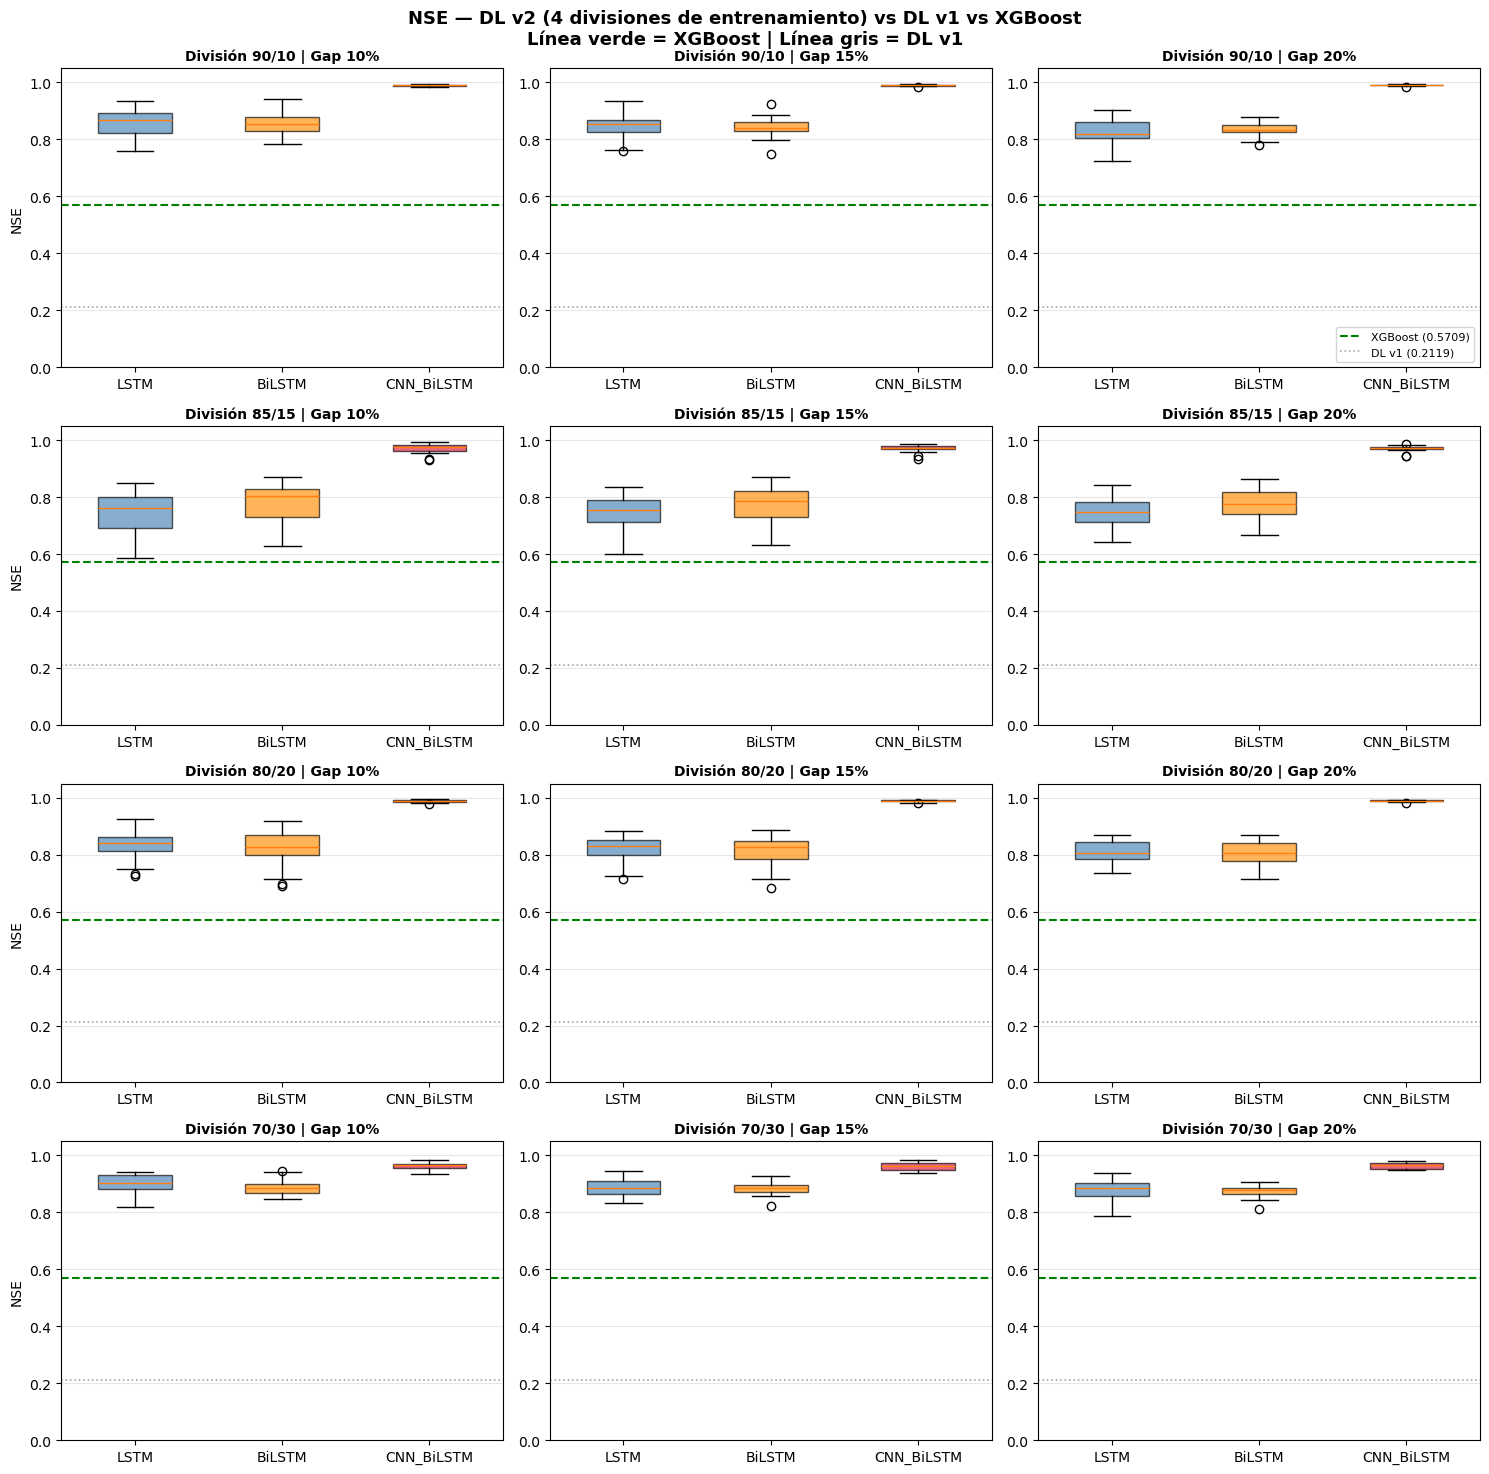

In [14]:
# ── Figura 1: NSE por división y pct_gap (4×3) ──────────────────────────────
fig, axes = plt.subplots(4, 3, figsize=(15, 15))
ref_xgb  = 0.5709
ref_v1   = 0.2119
colores  = {'LSTM_v2':'steelblue', 'BiLSTM_v2':'darkorange', 'CNN_BiLSTM_v2':'crimson'}

for row, div in enumerate(DIVISIONES):
    for col, pct in enumerate([10, 15, 20]):
        ax  = axes[row, col]
        sub = df_res_v2[(df_res_v2['division'] == div) & (df_res_v2['pct_gap'] == pct)]
        data   = [sub[sub['Modelo'] == m]['NSE'].values for m in colores]
        labels = [m.replace('_v2','') for m in colores]
        bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.5)
        for patch, color in zip(bp['boxes'], colores.values()):
            patch.set_facecolor(color); patch.set_alpha(0.65)
        ax.axhline(ref_xgb, color='green', ls='--', lw=1.5, label=f'XGBoost ({ref_xgb})')
        ax.axhline(ref_v1,  color='gray',  ls=':',  lw=1.2, alpha=0.7, label=f'DL v1 ({ref_v1})')
        ax.set_title(f'División {div} | Gap {pct}%', fontweight='bold', fontsize=10)
        ax.set_ylabel('NSE' if col == 0 else '', fontsize=10)
        ax.set_ylim(0, 1.05)
        ax.grid(axis='y', alpha=0.3)
        if row == 0 and col == 2:
            ax.legend(fontsize=8, loc='lower right')

plt.suptitle(
    'NSE — DL v2 (4 divisiones de entrenamiento) vs DL v1 vs XGBoost\n'
    'Línea verde = XGBoost | Línea gris = DL v1',
    fontweight='bold', fontsize=13
)
plt.tight_layout()
plt.savefig('fig1_NSE_divisiones.png', dpi=150, bbox_inches='tight')
plt.show()


#### Curvas de Entrenamiento por división y arquitectura

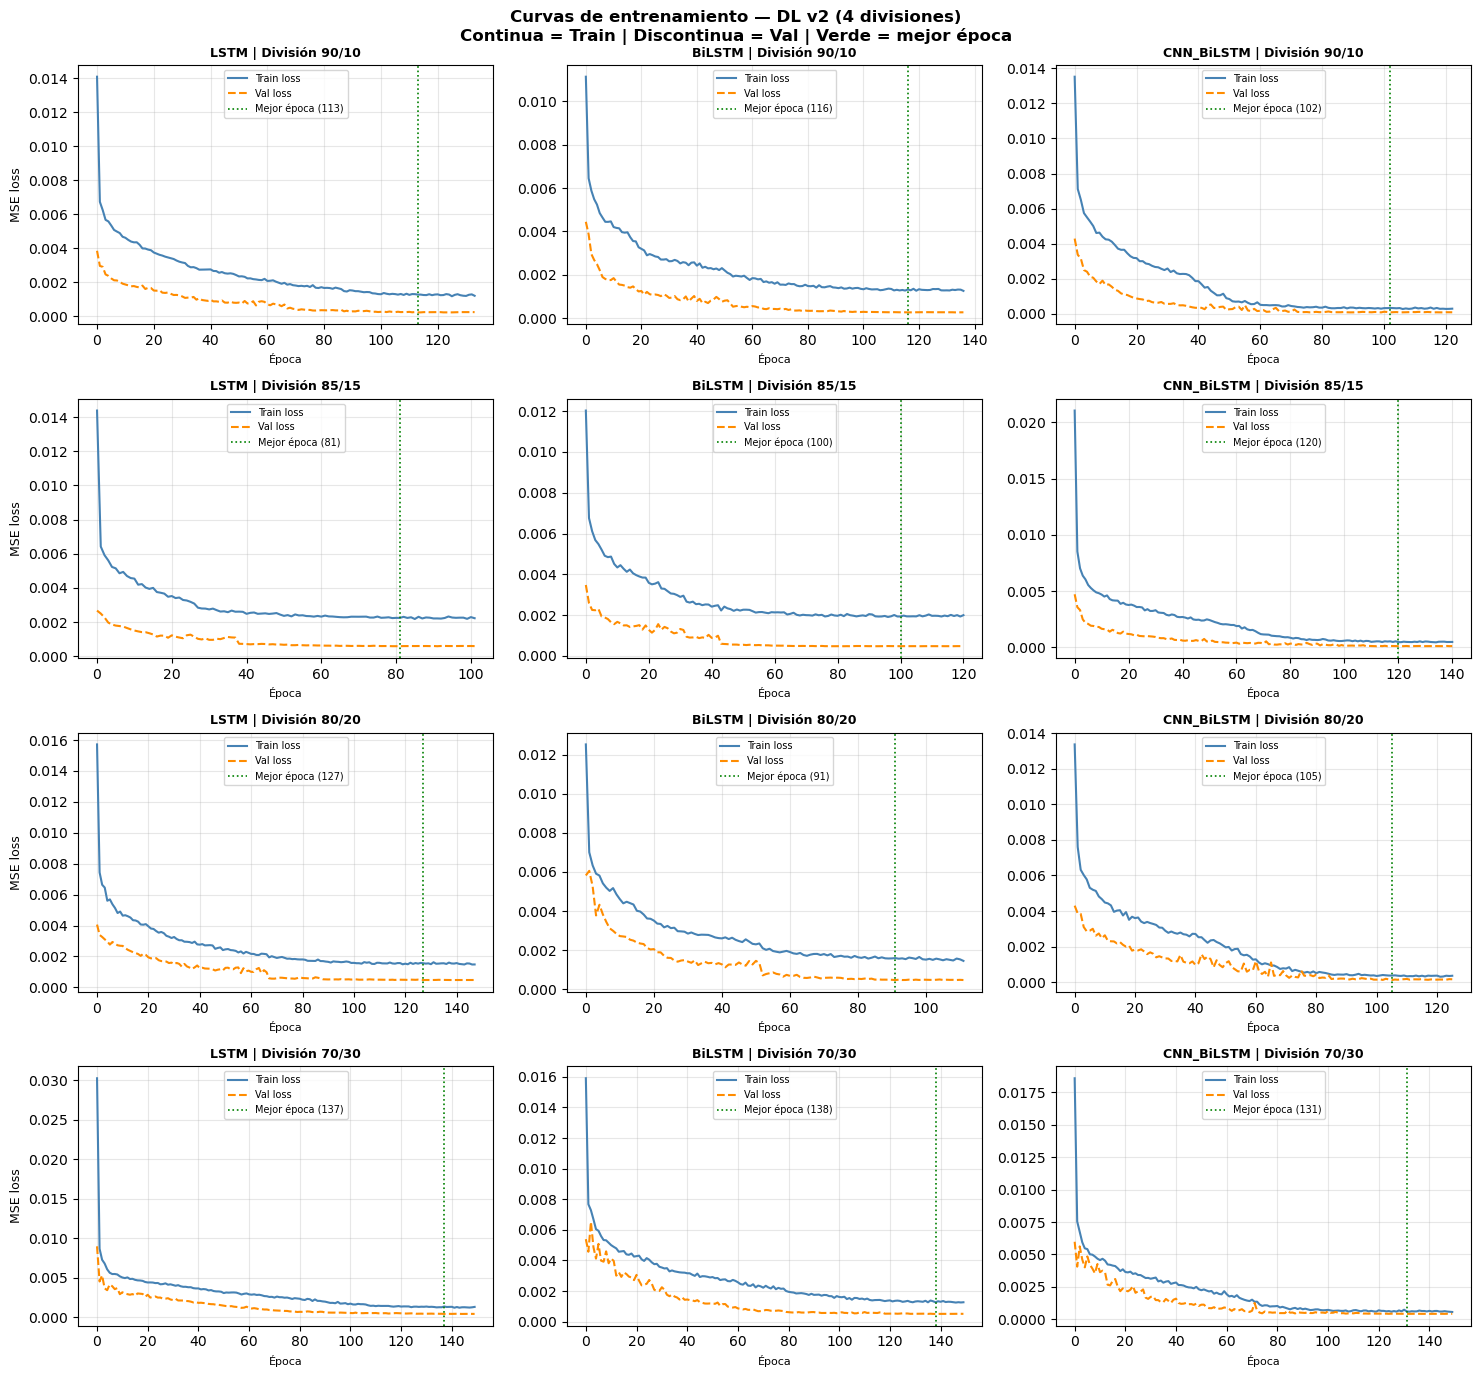

In [15]:
# ── Figura 2: Curvas de entrenamiento — 4 divisiones × 3 arquitecturas ───────
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
labels_split = {0.10: '90/10', 0.15: '85/15', 0.20: '80/20', 0.30: '70/30'}

for row, val_split in enumerate(VAL_SPLITS):
    for col, nombre_arq in enumerate(arquitecturas_v2):
        ax   = axes[row, col]
        hist = curvas_ent[(val_split, nombre_arq)]
        ax.plot(hist['loss'],     color='steelblue',   lw=1.5, label='Train loss')
        ax.plot(hist['val_loss'], color='darkorange',  lw=1.5, ls='--', label='Val loss')
        best_ep = np.argmin(hist['val_loss'])
        ax.axvline(best_ep, color='green', ls=':', lw=1.2,
                   label=f'Mejor época ({best_ep})')
        ax.set_title(
            f'{nombre_arq.replace("_v2","")} | División {labels_split[val_split]}',
            fontweight='bold', fontsize=9
        )
        ax.set_xlabel('Época', fontsize=8)
        ax.set_ylabel('MSE loss' if col == 0 else '', fontsize=9)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)

plt.suptitle(
    'Curvas de entrenamiento — DL v2 (4 divisiones)\n'
    'Continua = Train | Discontinua = Val | Verde = mejor época',
    fontweight='bold', fontsize=12
)
plt.tight_layout()
plt.savefig('fig2_curvas_entrenamiento_divisiones.png', dpi=150, bbox_inches='tight')
plt.show()


#### Figura Distribución visual de gaps

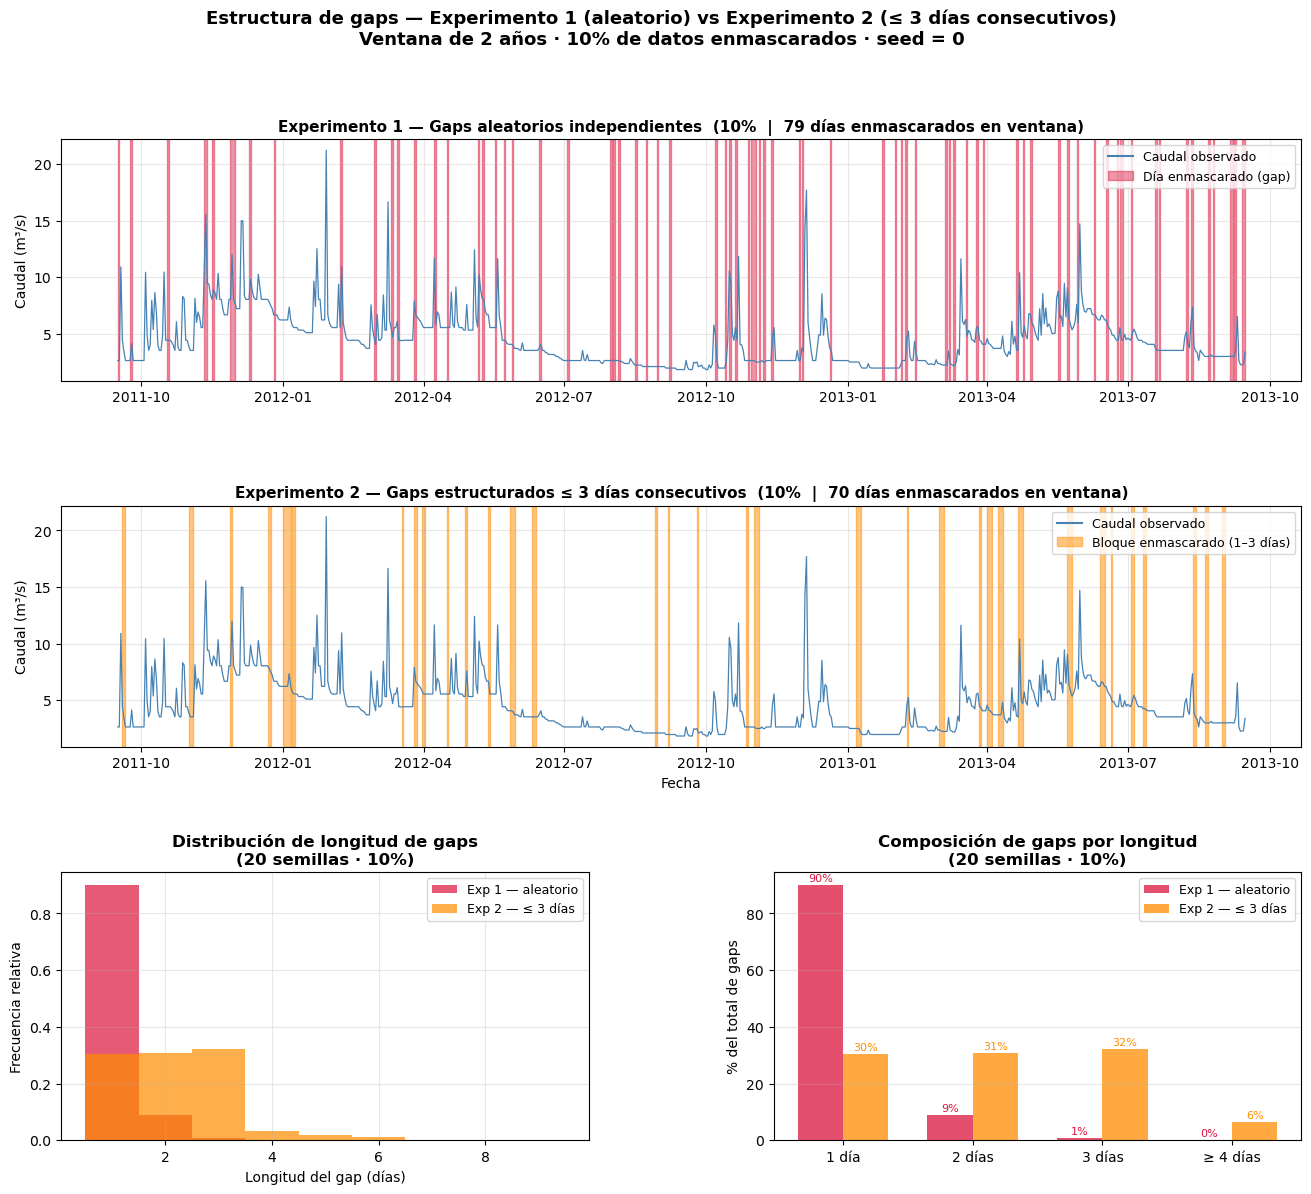

In [16]:
# ── Figura 5: Estructura de gaps — Exp 1 (aleatorio) vs Exp 2 (≤ 3 días) ────
from itertools import groupby as _grp
from matplotlib.patches import Patch

SEED_VIZ = 0
PCT_VIZ  = 0.10
N        = len(fechas_all)
fechas_dt = pd.to_datetime(fechas_all)

# Máscaras para un seed fijo
rng_e1  = np.random.default_rng(SEED_VIZ)
mask_e1 = rng_e1.random(N) < PCT_VIZ
mask_e2 = crear_mascara_gaps_cortos(N, PCT_VIZ, max_gap=3, seed=SEED_VIZ)

# Gap lengths acumulados (20 semillas, 10%)
gaps_e1_all, gaps_e2_all = [], []
for s in range(N_MASCARAS):
    gaps_e1_all.extend(contar_gaps(np.random.default_rng(s).random(N) < PCT_VIZ))
    gaps_e2_all.extend(contar_gaps(crear_mascara_gaps_cortos(N, PCT_VIZ, max_gap=3, seed=s)))

# Serie de caudal observado
obs_vals = np.expm1(np.clip(
    scaler_y.inverse_transform(y_all.reshape(-1, 1)).flatten(), 0, 20
))

# Ventana de 2 años para zoom
ini, fin = 600, 1330
f_zoom   = fechas_dt[ini:fin]
q_zoom   = obs_vals[ini:fin]
m1_zoom  = mask_e1[ini:fin]
m2_zoom  = mask_e2[ini:fin]

def sombrear_gaps(ax, fechas, mask, color, alpha=0.4):
    for val, grp in _grp(enumerate(mask), key=lambda x: x[1]):
        if val:
            idxs = [i for i, _ in grp]
            f0 = fechas[idxs[0]]
            f1 = fechas[min(idxs[-1]+1, len(fechas)-1)]
            ax.axvspan(f0, f1, color=color, alpha=alpha, zorder=1)

# ── Layout ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 13))
gs  = fig.add_gridspec(3, 2, height_ratios=[1.8, 1.8, 2],
                        hspace=0.5, wspace=0.35)

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, :])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[2, 1])

# ── Panel 1: Experimento 1 ────────────────────────────────────────────────────
ax1.plot(f_zoom, q_zoom, color='steelblue', lw=0.9, zorder=2, label='Caudal observado')
sombrear_gaps(ax1, f_zoom, m1_zoom, color='crimson', alpha=0.45)
ax1.set_title(
    f'Experimento 1 — Gaps aleatorios independientes  '
    f'(10%  |  {m1_zoom.sum()} días enmascarados en ventana)',
    fontweight='bold', fontsize=11
)
ax1.set_ylabel('Caudal (m³/s)', fontsize=10)
ax1.grid(alpha=0.3)
handles1 = [
    plt.Line2D([0],[0], color='steelblue', lw=1.5, label='Caudal observado'),
    Patch(color='crimson', alpha=0.45, label='Día enmascarado (gap)'),
]
ax1.legend(handles=handles1, fontsize=9, loc='upper right')

# ── Panel 2: Experimento 2 ────────────────────────────────────────────────────
ax2.plot(f_zoom, q_zoom, color='steelblue', lw=0.9, zorder=2, label='Caudal observado')
sombrear_gaps(ax2, f_zoom, m2_zoom, color='darkorange', alpha=0.5)
ax2.set_title(
    f'Experimento 2 — Gaps estructurados ≤ 3 días consecutivos  '
    f'(10%  |  {m2_zoom.sum()} días enmascarados en ventana)',
    fontweight='bold', fontsize=11
)
ax2.set_ylabel('Caudal (m³/s)', fontsize=10)
ax2.set_xlabel('Fecha', fontsize=10)
ax2.grid(alpha=0.3)
handles2 = [
    plt.Line2D([0],[0], color='steelblue', lw=1.5, label='Caudal observado'),
    Patch(color='darkorange', alpha=0.5, label='Bloque enmascarado (1–3 días)'),
]
ax2.legend(handles=handles2, fontsize=9, loc='upper right')

# ── Panel 3: Histograma de longitud de gaps ───────────────────────────────────
max_g = max(max(gaps_e1_all), max(gaps_e2_all))
bins  = np.arange(0.5, min(max_g, 12) + 1.5, 1)
ax3.hist(gaps_e1_all, bins=bins, color='crimson',    alpha=0.7,
         density=True, label='Exp 1 — aleatorio')
ax3.hist(gaps_e2_all, bins=bins, color='darkorange', alpha=0.7,
         density=True, label='Exp 2 — ≤ 3 días')
ax3.set_xlabel('Longitud del gap (días)', fontsize=10)
ax3.set_ylabel('Frecuencia relativa', fontsize=10)
ax3.set_title('Distribución de longitud de gaps\n(20 semillas · 10%)', fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)

# ── Panel 4: Composición por categoría ───────────────────────────────────────
cats     = ['1 día', '2 días', '3 días', '≥ 4 días']
t1, t2   = len(gaps_e1_all), len(gaps_e2_all)
pct_e1   = [sum(1 for g in gaps_e1_all if g == k)/t1*100 for k in [1,2,3]] + \
           [sum(1 for g in gaps_e1_all if g >= 4)/t1*100]
pct_e2   = [sum(1 for g in gaps_e2_all if g == k)/t2*100 for k in [1,2,3]] + \
           [sum(1 for g in gaps_e2_all if g >= 4)/t2*100]

x, w = np.arange(4), 0.35
bars1 = ax4.bar(x - w/2, pct_e1, w, color='crimson',    alpha=0.75, label='Exp 1 — aleatorio')
bars2 = ax4.bar(x + w/2, pct_e2, w, color='darkorange', alpha=0.75, label='Exp 2 — ≤ 3 días')
for bar in bars1:
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{bar.get_height():.0f}%', ha='center', va='bottom', fontsize=8, color='crimson')
for bar in bars2:
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{bar.get_height():.0f}%', ha='center', va='bottom', fontsize=8, color='darkorange')
ax4.set_xticks(x); ax4.set_xticklabels(cats, fontsize=10)
ax4.set_ylabel('% del total de gaps', fontsize=10)
ax4.set_title('Composición de gaps por longitud\n(20 semillas · 10%)', fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(axis='y', alpha=0.3)

plt.suptitle(
    'Estructura de gaps — Experimento 1 (aleatorio) vs Experimento 2 (≤ 3 días consecutivos)\n'
    'Ventana de 2 años · 10% de datos enmascarados · seed = 0',
    fontweight='bold', fontsize=13
)
plt.savefig('fig5_estructura_gaps_comparacion.png', dpi=150, bbox_inches='tight')
plt.show()


In [17]:
# Tabla de frecuencia absoluta de longitud de gaps
max_gap_tabla = max(max(gaps_e1_all), max(gaps_e2_all))
longitudes = list(range(1, max_gap_tabla + 1))

freq_e1 = [gaps_e1_all.count(k) for k in longitudes]
freq_e2 = [gaps_e2_all.count(k) for k in longitudes]

df_gaps = pd.DataFrame({
    'Longitud del gap (días)': longitudes,
    'Exp 1 — Aleatorio (frec. abs.)': freq_e1,
    'Exp 2 — ≤ 3 días (frec. abs.)': freq_e2,
})

df_gaps = df_gaps[(df_gaps['Exp 1 — Aleatorio (frec. abs.)'] > 0) |
                  (df_gaps['Exp 2 — ≤ 3 días (frec. abs.)'] > 0)].reset_index(drop=True)

df_gaps.style.set_caption('Frecuencia absoluta de longitud de gaps (20 semillas · 10%)')\
             .set_table_styles([{'selector': 'caption',
                                  'props': [('font-weight', 'bold'), ('font-size', '13px')]}])\
             .hide(axis='index')

Longitud del gap (días),Exp 1 — Aleatorio (frec. abs.),Exp 2 — ≤ 3 días (frec. abs.)
1,5017,855
2,502,868
3,46,908
4,7,96
5,0,53
6,0,29
7,0,3
9,0,1


In [18]:
# Tabla de frecuencia absoluta de longitud de gaps — 10%, 15% y 20%
from IPython.display import display

for pct_viz in [0.10, 0.15, 0.20]:
    # Recalcular gaps para este porcentaje
    gaps_e1 = []
    gaps_e2 = []
    for s in range(N_MASCARAS):
        gaps_e1.extend(contar_gaps(np.random.default_rng(s).random(N) < pct_viz))
        gaps_e2.extend(contar_gaps(crear_mascara_gaps_cortos(N, pct_viz, max_gap=3, seed=s)))

    max_gap_t = max(max(gaps_e1), max(gaps_e2))
    longs = list(range(1, max_gap_t + 1))

    df_g = pd.DataFrame({
        'Longitud del gap (días)':       longs,
        'Exp 1 — Aleatorio (frec. abs.)': [gaps_e1.count(k) for k in longs],
        'Exp 2 — ≤ 3 días (frec. abs.)': [gaps_e2.count(k) for k in longs],
    })
    df_g = df_g[(df_g['Exp 1 — Aleatorio (frec. abs.)'] > 0) |
                (df_g['Exp 2 — ≤ 3 días (frec. abs.)'] > 0)].reset_index(drop=True)

    display(
        df_g.style
        .set_caption(f'Frecuencia absoluta de longitud de gaps (20 semillas · {int(pct_viz*100)}%)')
        .set_table_styles([{'selector': 'caption',
                            'props': [('font-weight', 'bold'), ('font-size', '13px')]}])
        .hide(axis='index')
    )

Longitud del gap (días),Exp 1 — Aleatorio (frec. abs.),Exp 2 — ≤ 3 días (frec. abs.)
1,5017,855
2,502,868
3,46,908
4,7,96
5,0,53
6,0,29
7,0,3
9,0,1


Longitud del gap (días),Exp 1 — Aleatorio (frec. abs.),Exp 2 — ≤ 3 días (frec. abs.)
1,6723,1202
2,1032,1211
3,137,1298
4,20,195
5,3,93
6,0,53
7,0,11
8,0,5
9,0,4
10,0,1


Longitud del gap (días),Exp 1 — Aleatorio (frec. abs.),Exp 2 — ≤ 3 días (frec. abs.)
1,7963,1434
2,1599,1483
3,291,1617
4,61,316
5,13,171
6,2,90
7,1,29
8,0,11
9,0,9
10,0,5


#### Nueva Figura 3 — Serie con panel de error

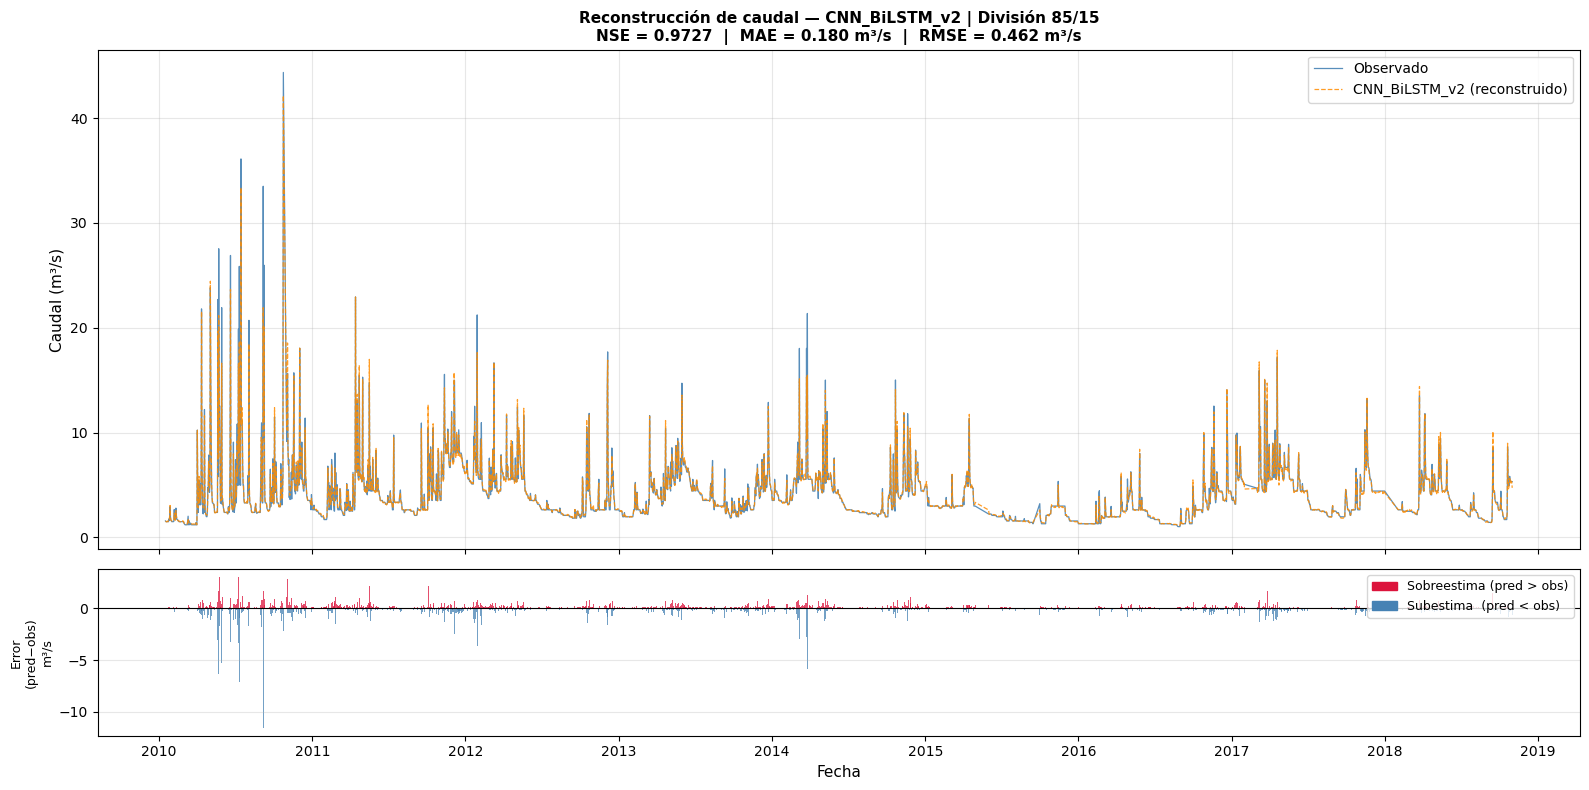

In [19]:
# ── Figura 3: Serie temporal observado vs reconstruido + panel de error ───────
# Usa predicciones del mejor modelo (85/15) — no requiere model_final
arq_plot = 'CNN_BiLSTM_v2'
vs_plot  = 0.15

y_pred_f_log, y_true_f_log = predicciones[(vs_plot, arq_plot)]

obs_f  = np.expm1(np.clip(y_true_f_log, 0, 20))
pred_f = np.maximum(np.expm1(np.clip(y_pred_f_log, 0, 20)), 0)
error_f   = pred_f - obs_f
fechas_dt = pd.to_datetime(fechas_all)

nse_f  = NSE(obs_f, pred_f)
mae_f  = mean_absolute_error(obs_f, pred_f)
rmse_f = np.sqrt(mean_squared_error(obs_f, pred_f))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(16, 8), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

# ── Panel superior: series ────────────────────────────────────────────────────
ax1.plot(fechas_dt, obs_f,  color='steelblue',  lw=0.9,
         label='Observado', alpha=0.9, zorder=2)
ax1.plot(fechas_dt, pred_f, color='darkorange', lw=0.9, ls='--',
         label=f'{arq_plot} (reconstruido)', alpha=0.85, zorder=3)
ax1.set_ylabel('Caudal (m³/s)', fontsize=11)
ax1.legend(fontsize=10, loc='upper right')
ax1.grid(alpha=0.3)
ax1.set_title(
    f'Reconstrucción de caudal — {arq_plot} | División 85/15\n'
    f'NSE = {nse_f:.4f}  |  MAE = {mae_f:.3f} m³/s  |  RMSE = {rmse_f:.3f} m³/s',
    fontweight='bold', fontsize=11
)

# ── Panel inferior: error (pred − obs) ───────────────────────────────────────
colores_err = ['crimson' if e >= 0 else 'steelblue' for e in error_f]
ax2.bar(fechas_dt, error_f, color=colores_err, width=2, alpha=0.75)
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylabel('Error\n(pred−obs)\nm³/s', fontsize=9)
ax2.set_xlabel('Fecha', fontsize=11)
ax2.grid(axis='y', alpha=0.3)

from matplotlib.patches import Patch
ax2.legend(handles=[
    Patch(color='crimson',   label='Sobreestima (pred > obs)'),
    Patch(color='steelblue', label='Subestima  (pred < obs)'),
], fontsize=9, loc='upper right')

plt.tight_layout()
plt.savefig('fig3_serie_error.png', dpi=150, bbox_inches='tight')
plt.show()



#### Serie completa con reconstrucción

In [20]:
%matplotlib inline

In [21]:
# ── Entrenamiento del modelo final (con cache en disco) ───────────────────────
import os

MODEL_PATH = '../modelos/modelo_cnn_bilstm_v2_Buga.keras'
FORCE_RETRAIN = False  # poner en True para forzar reentrenamiento aunque exista el cache

if os.path.exists(MODEL_PATH) and not FORCE_RETRAIN:
    _m = tf.keras.models.load_model(MODEL_PATH)
    print(f'Modelo cargado desde cache: {MODEL_PATH}')
else:
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    hp_f = HP_OPTIMOS['CNN_BiLSTM_v2']
    _m = build_cnn_bilstm_v2(input_shape,
                              units=hp_f['units'], dropout=hp_f['dropout'],
                              filters=hp_f['filters'], kernel_size=hp_f['kernel_size'],
                              dense_units=hp_f['dense_units'])
    _m.compile(optimizer=Adam(learning_rate=hp_f['learning_rate']), loss='mse')
    _m.fit(X_all, y_all, epochs=200, batch_size=BATCH_SIZE,
           validation_split=0.10,
           callbacks=get_callbacks(patience_es=25, patience_lr=12),
           verbose=1)
    _m.save(MODEL_PATH)
    print(f'Modelo entrenado y guardado en cache: {MODEL_PATH}')

mejor_arq_v2 = 'CNN_BiLSTM_v2'


Modelo cargado desde cache: modelo_cnn_bilstm_v2_final.keras


  Secuencias a reconstruir: 115

📋 Estado de df_final:
Fuente
Observado                       3100
No reconstruido (gap >100d)     2618
Reconstruido (CNN_BiLSTM_v2)     115
   NaN en Caudal_m3s: 2618

   Puntos observados no NaN : 3100
   Puntos reconstruidos no NaN: 115


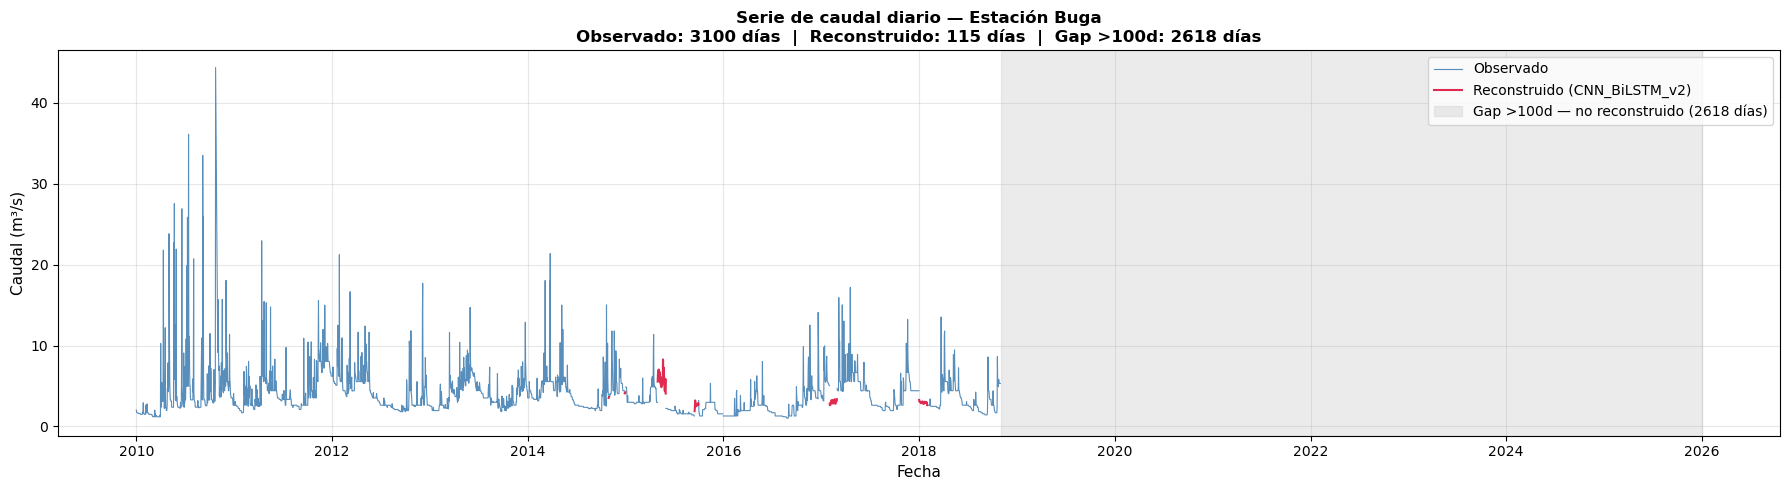

In [22]:
# ── Figura 4: Serie completa — observado + reconstruido ──────────────────────
from matplotlib.patches import Patch

def _get_mask_gaps(serie, umbral=100):
    """Marca True los días dentro de gaps consecutivos de NaN con longitud <= umbral."""
    mask = pd.Series(False, index=serie.index)
    en_gap, inicio = False, None
    for fecha, valor in serie.items():
        if pd.isna(valor):
            if not en_gap: inicio, en_gap = fecha, True
        else:
            if en_gap:
                if (fecha - inicio).days <= umbral: mask[inicio:fecha] = True
                en_gap = False
    # Caso borde: gap al final de la serie (nunca se cierra con un valor obs.)
    if en_gap and inicio is not None:
        fin = serie.index[-1]
        if (fin - inicio).days <= umbral:
            mask[inicio:fin] = True
    return mask

serie_caudal = df_full[TARGET]
mask_rec     = _get_mask_gaps(serie_caudal) & serie_caudal.isna()
arr_sc       = scaler_X.transform(df_full[FEATURES_V2].values.astype(np.float32))
total_len    = WINDOW + HORIZON + 1
pred_seqs, pred_fechas = [], []

for i in range(WINDOW, len(df_full) - HORIZON):
    fecha = df_full.index[i]
    if not mask_rec.get(fecha, False): continue
    seq = arr_sc[i - WINDOW : i + HORIZON + 1]
    if seq.shape[0] == total_len:
        pred_seqs.append(seq); pred_fechas.append(fecha)

print(f'  Secuencias a reconstruir: {len(pred_seqs)}')

Q_rec  = serie_caudal.values.copy().astype(float)
fuente = np.array(['Observado'] * len(df_full), dtype=object)

if pred_seqs:
    y_sc  = _m.predict(np.array(pred_seqs, dtype=np.float32), verbose=0).flatten()
    y_m3s = np.maximum(np.expm1(
        scaler_y.inverse_transform(y_sc.reshape(-1,1)).flatten()), 0)
    for fecha, val in zip(pred_fechas, y_m3s):
        idx = df_full.index.get_loc(fecha)
        Q_rec[idx] = val; fuente[idx] = 'Reconstruido (CNN_BiLSTM_v2)'

for i, fecha in enumerate(df_full.index):
    if serie_caudal.isna().get(fecha, False) and not mask_rec.get(fecha, False):
        fuente[i] = 'No reconstruido (gap >100d)'

df_final = pd.DataFrame({'Caudal_m3s': Q_rec, 'Fuente': fuente}, index=df_full.index)

# ── Diagnóstico antes de graficar ─────────────────────────────────────────────
print('\n📋 Estado de df_final:')
print(df_final['Fuente'].value_counts().to_string())
print(f'   NaN en Caudal_m3s: {df_final["Caudal_m3s"].isna().sum()}')

# ── Gráfico ───────────────────────────────────────────────────────────────────
obs_mask  = df_final['Fuente'] == 'Observado'
rec_mask  = df_final['Fuente'].str.startswith('Reconstruido')
nrec_mask = df_final['Fuente'].str.startswith('No recon')

q_obs_plot = df_final['Caudal_m3s'].where(obs_mask)
q_rec_plot = df_final['Caudal_m3s'].where(rec_mask)

print(f'\n   Puntos observados no NaN : {q_obs_plot.notna().sum()}')
print(f'   Puntos reconstruidos no NaN: {q_rec_plot.notna().sum()}')

fig, ax = plt.subplots(figsize=(18, 5))

ax.plot(df_final.index, q_obs_plot, color='steelblue', lw=0.8,
        label='Observado', alpha=0.9, zorder=2)
ax.plot(df_final.index, q_rec_plot, color='crimson', lw=1.5,
        label=f'Reconstruido ({mejor_arq_v2})', alpha=0.9, zorder=3)

in_gap = False
for fecha, flag in nrec_mask.items():
    if flag and not in_gap:
        gap_ini = fecha; in_gap = True
    elif not flag and in_gap:
        ax.axvspan(gap_ini, fecha, color='lightgray', alpha=0.45, zorder=0)
        in_gap = False
if in_gap:
    ax.axvspan(gap_ini, df_final.index[-1], color='lightgray', alpha=0.45, zorder=0)

n_obs  = obs_mask.sum()
n_rec  = rec_mask.sum()
n_nrec = nrec_mask.sum()

handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(color='lightgray', alpha=0.45,
                     label=f'Gap >100d — no reconstruido ({n_nrec} días)'))
ax.legend(handles=handles, fontsize=10, loc='upper right')
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Caudal (m³/s)', fontsize=11)
ax.set_title(
    f'Serie de caudal diario — Estación Buga\n'
    f'Observado: {n_obs} días  |  Reconstruido: {n_rec} días  |  Gap >100d: {n_nrec} días',
    fontweight='bold', fontsize=12
)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig4_serie_completa_reconstruida.png', dpi=150, bbox_inches='tight')

from IPython.display import display as ipy_display
ipy_display(fig)
plt.close(fig)


In [23]:
# ── Tabla por año y mes de datos reconstruidos ───────────────────────────────
MESES = {1:'Ene',2:'Feb',3:'Mar',4:'Abr',5:'May',6:'Jun',
          7:'Jul',8:'Ago',9:'Sep',10:'Oct',11:'Nov',12:'Dic'}

print('\n' + '='*110)
print('📋 TABLA AÑO × MES — Estado de la serie reconstruida (Estación Buga)')
print('='*110)

df_anio = df_final.copy()
df_anio['Año'] = df_anio.index.year
df_anio['Mes'] = df_anio.index.month

resumen_anual = []
for (anio, mes), grp in df_anio.groupby(['Año', 'Mes']):
    n_total  = len(grp)
    n_obs    = (grp['Fuente'] == 'Observado').sum()
    n_rec    = grp['Fuente'].str.startswith('Reconstruido').sum()
    n_nrec   = grp['Fuente'].str.startswith('No recon').sum()
    pct_comp = round((n_obs + n_rec) / n_total * 100, 1)
    q_obs_mean   = grp.loc[grp['Fuente'] == 'Observado',              'Caudal_m3s'].mean()
    q_rec_mean   = grp.loc[grp['Fuente'].str.startswith('Reconstruido'), 'Caudal_m3s'].mean()
    q_total_mean = grp['Caudal_m3s'].mean()
    resumen_anual.append({
        'Año':              anio,
        'Mes':              MESES[mes],
        'Total días':       n_total,
        'Observados':       n_obs,
        'Reconstruidos':    n_rec,
        'No recon. (>100d)': n_nrec,
        '% Completitud':    pct_comp,
        'Q̄ obs (m³/s)':    round(q_obs_mean,   3) if n_obs > 0 else '-',
        'Q̄ rec (m³/s)':    round(q_rec_mean,   3) if n_rec > 0 else '-',
        'Q̄ total (m³/s)':  round(q_total_mean, 3),
    })

df_resumen_anual = pd.DataFrame(resumen_anual)

# ── Imprimir con separador visual entre años ──────────────────────────────────
anio_prev = None
for _, row in df_resumen_anual.iterrows():
    if row['Año'] != anio_prev:
        if anio_prev is not None:
            print('-'*110)
        print(f"  {'Año':>4}  {'Mes':>3}  {'Total':>6}  {'Obs':>5}  "
              f"{'Rec':>5}  {'No rec':>7}  {'Complet%':>9}  "
              f"{'Q̄obs':>10}  {'Q̄rec':>10}  {'Q̄tot':>10}")
        anio_prev = row['Año']
    print(f"  {row['Año']:>4}  {row['Mes']:>3}  {row['Total días']:>6}  "
          f"{row['Observados']:>5}  {row['Reconstruidos']:>5}  "
          f"{row['No recon. (>100d)']:>7}  {row['% Completitud']:>9.1f}  "
          f"{str(row['Q̄ obs (m³/s)']):>10}  {str(row['Q̄ rec (m³/s)']):>10}  "
          f"{row['Q̄ total (m³/s)']:>10.3f}")

print('='*110)

# ── Totales globales ──────────────────────────────────────────────────────────
tot_obs  = df_resumen_anual['Observados'].sum()
tot_rec  = df_resumen_anual['Reconstruidos'].sum()
tot_nrec = df_resumen_anual['No recon. (>100d)'].sum()
tot_dias = df_resumen_anual['Total días'].sum()
print(f'  Total observados:    {tot_obs} días')
print(f'  Total reconstruidos: {tot_rec} días')
print(f'  No reconstruidos:    {tot_nrec} días')
print(f'  Completitud global:  {(tot_obs + tot_rec) / tot_dias * 100:.1f}%')
print('='*110)

# ── Exportar a Excel ──────────────────────────────────────────────────────────
df_resumen_anual.to_excel('tabla_anual_mensual_Buga.xlsx', index=False)
print('\n→ Exportado: tabla_anual_mensual_Buga.xlsx')



📋 TABLA AÑO × MES — Estado de la serie reconstruida (Estación Buga)
   Año  Mes   Total    Obs    Rec   No rec   Complet%       Q̄obs       Q̄rec       Q̄tot
  2010  Ene      31     31      0        0      100.0       1.681           -       1.681
  2010  Feb      27     27      0        0      100.0       1.664           -       1.664
  2010  Mar      31     31      0        0      100.0       1.279           -       1.279
  2010  Abr      30     30      0        0      100.0       4.771           -       4.771
  2010  May      31     31      0        0      100.0       7.247           -       7.247
  2010  Jun      30     30      0        0      100.0       3.941           -       3.941
  2010  Jul      31     31      0        0      100.0       7.715           -       7.715
  2010  Ago      31     31      0        0      100.0       3.443           -       3.443
  2010  Sep      30     30      0        0      100.0       5.933           -       5.933
  2010  Oct      24     24     

In [24]:
# ── Tabla de gaps de caudal faltante y días susceptibles de reconstrucción ──
UMBRAL_RECON = 100  # días máx. de gap consecutivo reconstruible (ver _get_mask_gaps)

serie_gaps = df_full[TARGET]

gaps_info = []
en_gap, inicio = False, None
for fecha, valor in serie_gaps.items():
    if pd.isna(valor):
        if not en_gap:
            inicio, en_gap = fecha, True
    else:
        if en_gap:
            fin = fecha - pd.Timedelta(days=1)
            gaps_info.append((inicio, fin, (fin - inicio).days + 1))
            en_gap = False
if en_gap and inicio is not None:
    fin = serie_gaps.index[-1]
    gaps_info.append((inicio, fin, (fin - inicio).days + 1))

df_gaps = pd.DataFrame(gaps_info, columns=['Fecha inicio', 'Fecha fin', 'N_dias'])
df_gaps['Susceptible_reconstruccion'] = np.where(df_gaps['N_dias'] <= UMBRAL_RECON, 'Si', 'No')

if 'df_final' in dir():
    dias_reconstruidos = []
    for _, fila in df_gaps.iterrows():
        sub = df_final.loc[fila['Fecha inicio']:fila['Fecha fin'], 'Fuente']
        dias_reconstruidos.append(int(sub.str.startswith('Reconstruido').sum()))
    df_gaps['Dias_reconstruidos'] = dias_reconstruidos

print('')
print('=' * 100)
print('TABLA DE GAPS DE CAUDAL FALTANTE - Estacion Buga  (umbral reconstruccion = %d dias)' % UMBRAL_RECON)
print('=' * 100)
print(df_gaps.to_string(index=False))
print('=' * 100)

n_gaps = len(df_gaps)
n_dias_total = int(df_gaps['N_dias'].sum())
n_gaps_susc = int((df_gaps['Susceptible_reconstruccion'] == 'Si').sum())
n_dias_susc = int(df_gaps.loc[df_gaps['Susceptible_reconstruccion'] == 'Si', 'N_dias'].sum())

print('Total de gaps:                        %d' % n_gaps)
print('Total de dias faltantes:              %d' % n_dias_total)
print('Gaps susceptibles (<= %d d):           %d' % (UMBRAL_RECON, n_gaps_susc))
print('Dias susceptibles de reconstruccion:  %d' % n_dias_susc)
print('=' * 100)

df_gaps.to_excel('tabla_gaps_faltantes_Buga.xlsx', index=False)
print('')
print('Exportado: tabla_gaps_faltantes_Buga.xlsx')



TABLA DE GAPS DE CAUDAL FALTANTE - Estacion Buga  (umbral reconstruccion = 100 dias)
Fecha inicio  Fecha fin  N_dias Susceptible_reconstruccion  Dias_reconstruidos
  2012-10-31 2012-10-31       1                         Si                   1
  2014-01-31 2014-01-31       1                         Si                   1
  2014-10-30 2014-10-31       2                         Si                   2
  2014-12-29 2014-12-31       3                         Si                   3
  2015-04-22 2015-04-22       1                         Si                   1
  2015-05-01 2015-05-31      31                         Si                  31
  2015-09-16 2015-09-30      15                         Si                  15
  2015-12-31 2015-12-31       1                         Si                   1
  2017-02-01 2017-02-28      28                         Si                  28
  2017-05-31 2017-05-31       1                         Si                   1
  2018-01-01 2018-01-31      31              